# Bike-sharing demand: all five phases

**Question:** How many bikes will be rented in an hour, and is that hour unusually busy?

Use the notebook outline to jump to a phase. Run all cells from the top with the project `.venv` kernel.

| Phase | What it does | What the next phase receives |
|---|---|---|
| One | Fits a linear model using our own gradient descent | Weights and training settings |
| Two | Adds selected squared and cubic weather terms | Degree 3 and its feature list |
| Three | Compares model sizes and checks later dates | Fit diagnosis and target degree 4 |
| Four | Compares Lasso, Ridge and Elastic Net | The 57 features kept by Lasso |
| Five | Predicts unusually high demand | Classifier, final count CSV and report |

**Words used below:** a *feature* is an input column; a *weight* is a learned coefficient; *validation* is the held-out data used to compare settings; *scaling* puts features on similar numerical ranges. A *penalty* discourages large coefficients. RMSE is error in rentals/hour (lower is better); R² measures explained variation (higher is better).

**Files to submit:** this notebook, `project_report.pdf` (six pages), and root `sample_submission.csv`. Original inputs stay in `data/`; saved phase results stay in `artifacts/`. The optional +5% asymmetric-cost experiment is included in Phase One.

## Phase One: linear regression with gradient descent

**Goal:** Fit the baseline and create the required seeded split.

### Expectation

*Kept from the phase’s first run.*

Before running: a linear model should explain part of demand using hour, calendar and weather information. Encoding hours as categories should capture commuting peaks better than treating hour as a straight numerical slope. Temperature and feels-like temperature may be redundant. Scaling should make gradient descent stable, while a large learning rate may diverge. The required random split may be optimistic for future periods; the chronological comparison belongs to Phase Three.

### 1. Imports and team seed
Load the libraries. Sort the three IDs as strings, join them with underscores, hash the result and take modulo 100000. This gives **29578**. We also check the example seed from the brief. Scikit-learn supplies the required split; it does not fit our regression models.

In [1]:
import hashlib
import json
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

ids = sorted(["16003585", "16003110", "14004179"])
concatenated_string = "_".join(ids)
seed = int(hashlib.sha256(concatenated_string.encode()).hexdigest(), 16) % 100000
assert int(hashlib.sha256(b"34521_40218_41190").hexdigest(), 16) % 100000 == 41698
assert seed == 29578
random.seed(seed)
np.random.seed(seed)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11, "axes.grid": True, "grid.alpha": 0.2})
print("Python:", sys.executable)
print("Sorted IDs:", ids, "| Seed:", seed)


Python: D:\machine-learning-project-I\.venv\Scripts\python.exe
Sorted IDs: ['14004179', '16003110', '16003585'] | Seed: 29578


### 2. Read and check the data
Read the three supplied CSVs. Check missing values, duplicate rows, IDs, column names and test-row order. `cnt` is the target, not an input. Combine date and hour to inspect the timeline. Missing hours are not assumed to have zero rentals, so we do not invent rows.

In [2]:
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "train.csv").exists():
    raise FileNotFoundError("Run the notebook from the project folder containing data/train.csv")
DATA_DIR = PROJECT_DIR / "data"
train_all = pd.read_csv(DATA_DIR / "train.csv")
test_X = pd.read_csv(DATA_DIR / "test.csv")
submission_template = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert "cnt" in train_all and "cnt" not in test_X
assert list(test_X.columns) == [c for c in train_all.columns if c != "cnt"]
assert submission_template["instant"].equals(test_X["instant"])
assert train_all["instant"].is_unique and test_X["instant"].is_unique
assert set(train_all.instant).isdisjoint(test_X.instant)
assert train_all.isna().sum().sum() == 0, "Inspect missing values before modeling"
assert train_all.duplicated().sum() == 0
assert (train_all.cnt >= 0).all()
display(pd.DataFrame({"file": ["train.csv", "test.csv", "sample_submission.csv"],
                      "rows": [len(train_all), len(test_X), len(submission_template)],
                      "columns": [train_all.shape[1], test_X.shape[1], submission_template.shape[1]]}))
display(train_all.head())
display(pd.DataFrame({"dtype": train_all.dtypes.astype(str), "missing": train_all.isna().sum()}))
timestamps = pd.to_datetime(train_all.dteday) + pd.to_timedelta(train_all.hr, unit="h")
assert timestamps.is_unique
full_timeline = pd.date_range(timestamps.min(), timestamps.max(), freq="h")
print("Labeled time coverage:", timestamps.min(), "to", timestamps.max())
print("Hours absent from labeled file:", len(full_timeline.difference(pd.DatetimeIndex(timestamps))))
print("Absence may include held-out test hours and operational gaps; do not assume zero demand.")


,file,rows,columns
0,train.csv,10886,15
1,test.csv,574,14
2,sample_submission.csv,574,2


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


,dtype,missing
instant,int64,0
dteday,str,0
season,int64,0
yr,int64,0
mnth,int64,0
hr,int64,0
holiday,int64,0
weekday,int64,0
workingday,int64,0
weathersit,int64,0


Labeled time coverage: 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Hours absent from labeled file: 6370
Absence may include held-out test hours and operational gaps; do not assume zero demand.


### 3. Make the required split
Call `train_test_split` once with `test_size=0.20` and seed **29578**. This gives **8,708 training rows** and **2,178 validation rows**. All later tuning uses this same split. The hidden test file is never split or used to choose settings.

In [3]:
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=seed)
train_df = train_df.copy()
val_df = val_df.copy()
assert set(train_df.instant).isdisjoint(val_df.instant)
assert len(train_df) + len(val_df) == len(train_all)
print("Training rows:", len(train_df), "| Validation rows:", len(val_df))


Training rows: 8708 | Validation rows: 2178


### 4. Turn raw columns into model inputs
- Use one-hot columns for hour, season, weather, weekday and month. This gives categories separate effects instead of treating their codes as distances.
- Keep year, holiday and working-day flags, plus continuous weather values. Extract day-of-month from the date; year and month are already available.
- Leave out the record ID. Combine weather codes 3 and 4 as adverse weather: code 4 is absent from training, so it cannot have a separately learned effect.
- Learn means and standard deviations on training only. Apply the same scaling and column order to validation.
- Drop constant columns if any exist, then add a column of ones for the intercept (the model's starting level).

The target stays in rentals/hour. An unknown category raises an error instead of silently becoming clear weather. The later regularization phase will check overlapping inputs.

In [4]:
categorical_columns = ["hr", "season", "weathersit", "weekday", "mnth"]
numeric_columns = ["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed", "day_of_month"]
def categorical_values(frame, column):
    return frame[column].replace({4: 3}) if column == "weathersit" else frame[column]

category_levels = {c: sorted(categorical_values(train_df, c).unique().tolist()) for c in categorical_columns}

def encode_features(frame):
    dates = pd.to_datetime(frame["dteday"], errors="raise")
    numeric = frame[["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed"]].astype(float).copy()
    numeric["day_of_month"] = dates.dt.day.astype(float)
    for column, levels in category_levels.items():
        values = categorical_values(frame, column)
        unknown = set(values.unique()) - set(levels)
        if unknown:
            raise ValueError(f"Unseen categories in {column}: {unknown}; review encoding")
        for level in levels[1:]:
            numeric[f"{column}_{level}"] = (values == level).astype(float)
    return numeric

encoded_train = encode_features(train_df)
encoded_val = encode_features(val_df)
train_std = encoded_train.std(ddof=0)
constant_columns = train_std.index[train_std == 0].tolist()
feature_names = [c for c in encoded_train if c not in constant_columns]
feature_mean = encoded_train[feature_names].mean()
feature_scale = train_std[feature_names]

def design_matrix(encoded):
    scaled = (encoded[feature_names] - feature_mean) / feature_scale
    return np.column_stack([np.ones(len(scaled)), scaled.to_numpy(dtype=float)])

X_train = design_matrix(encoded_train)
X_val = design_matrix(encoded_val)
y_train = train_df.cnt.to_numpy(dtype=float)
y_val = val_df.cnt.to_numpy(dtype=float)
weight_names = ["intercept"] + feature_names
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert np.allclose(X_train[:, 1:].mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_train[:, 1:].std(axis=0), 1)
print("Design matrices:", X_train.shape, X_val.shape)
print("Dropped constant columns:", constant_columns)
display(train_df[["temp", "atemp", "yr"]].corr().round(3))


Design matrices: (8708, 54) (2178, 54)
Dropped constant columns: []


,temp,atemp,yr
temp,1.000,0.986,0.064
atemp,0.986,1.000,0.062
yr,0.064,0.062,1.000


### 5. Fit with gradient descent
The model predicts $\hat y=Xw$. Its loss is half the mean squared error:

$$J(w)=\frac{1}{2m}\|Xw-y\|^2,\qquad \nabla J=\frac{X^T(Xw-y)}{m}.$$

At each step, subtract `learning_rate * gradient` from the weights. We start at zero. `X.T @ X / m` and `X.T @ y / m` are calculated once to make the same full-batch updates faster.

`L` is the largest eigenvalue of the training Hessian: it describes the steepest direction of this quadratic loss. Test rates `0.1/L`, `0.5/L`, `1/L`, plus the deliberately excessive `2.2/L`. Rates below `2/L` are stable here. Stop after relative loss changes below `1e-10` for 20 steps, or at 12,000 updates. Select the converged run with lowest validation RMSE.

In [5]:
def gradient_descent(X, y, learning_rate, max_iter=12000, tol=1e-10, patience=20, initial_weights=None):
    if learning_rate <= 0 or max_iter < 1 or patience < 1:
        raise ValueError("Learning rate, iteration limit and patience must be positive")
    m, p = X.shape
    weights = np.zeros(p) if initial_weights is None else np.array(initial_weights, dtype=float, copy=True)
    if weights.shape != (p,):
        raise ValueError("Initial weights must match the design matrix columns")
    hessian = X.T @ X / m
    rhs = X.T @ y / m
    # Algebraically equivalent to full-batch gradients; avoids repeated row scans.
    loss = float(np.mean((X @ weights - y) ** 2) / 2)
    losses = [loss]
    initial_loss = max(loss, 1.0)
    stable_steps = 0
    status = "max_iter"
    for iteration in range(1, max_iter + 1):
        candidate = weights - learning_rate * (hessian @ weights - rhs)
        # Exact quadratic change in J, avoiding subtracting large quadratic terms.
        delta = candidate - weights
        candidate_loss = loss + float(delta @ (hessian @ weights - rhs) + 0.5 * delta @ hessian @ delta)
        if not np.isfinite(candidate_loss) or candidate_loss > initial_loss * 1e8:
            status = "diverged"
            break
        change = abs(loss - candidate_loss) / max(abs(loss), 1.0)
        weights, loss = candidate, candidate_loss
        losses.append(loss)
        stable_steps = stable_steps + 1 if change < tol else 0
        if stable_steps >= patience:
            status = "converged"
            break
    return {"weights": weights, "loss_history": np.array(losses), "iterations": len(losses)-1,
            "status": status, "learning_rate": float(learning_rate)}

def regression_metrics(y, predictions):
    errors = y - predictions
    sse = float(errors @ errors)
    sst = float(((y - y.mean()) ** 2).sum())
    return {"R2": 1 - sse / sst, "RMSE": float(np.sqrt(sse / len(y)))}

L = float(np.linalg.eigvalsh(X_train.T @ X_train / len(y_train)).max())
max_iter, tolerance, patience = 12000, 1e-10, 20
rate_factors = [0.1, 0.5, 1.0, 2.2]
runs, rows = [], []
for factor in rate_factors:
    run = gradient_descent(X_train, y_train, factor / L, max_iter, tolerance, patience)
    runs.append(run)
    scores = regression_metrics(y_val, X_val @ run["weights"]) if run["status"] != "diverged" else {"R2": np.nan, "RMSE": np.nan}
    rows.append({"rate_factor": factor, "learning_rate": run["learning_rate"], "iterations": run["iterations"],
                 "status": run["status"], "validation_R2": scores["R2"], "validation_RMSE": scores["RMSE"]})
search_results = pd.DataFrame(rows)
display(search_results.round(6))
eligible = search_results.index[search_results.status == "converged"]
assert len(eligible), "No converged run; revise training settings before continuing"
best_index = search_results.loc[eligible, "validation_RMSE"].idxmin()
best_run = runs[best_index]
phase_one_weights = best_run["weights"].copy()
print("Training-derived stable learning-rate bound:", 2 / L)
print("Selected learning rate:", best_run["learning_rate"])


,rate_factor,learning_rate,iterations,status,validation_R2,validation_RMSE
0,0.1,0.027631,9938,converged,0.697951,99.464913
1,0.5,0.138156,2506,converged,0.697949,99.465222
2,1.0,0.276312,1371,converged,0.697949,99.465300
3,2.2,0.607887,59,diverged,NaN,NaN


Training-derived stable learning-rate bound: 0.5526242245366456
Selected learning rate: 0.027631211226832285


### 6. Check that the optimizer works
Plot loss while training. A finite-difference check changes each weight slightly and checks our gradient formula. A separate least-squares calculation gives a reference training optimum; it does **not** supply the weights used for predictions. Require training RMSE to agree within 0.001 rentals/hour. This catches slow or incorrect optimization that a flat loss curve might hide.

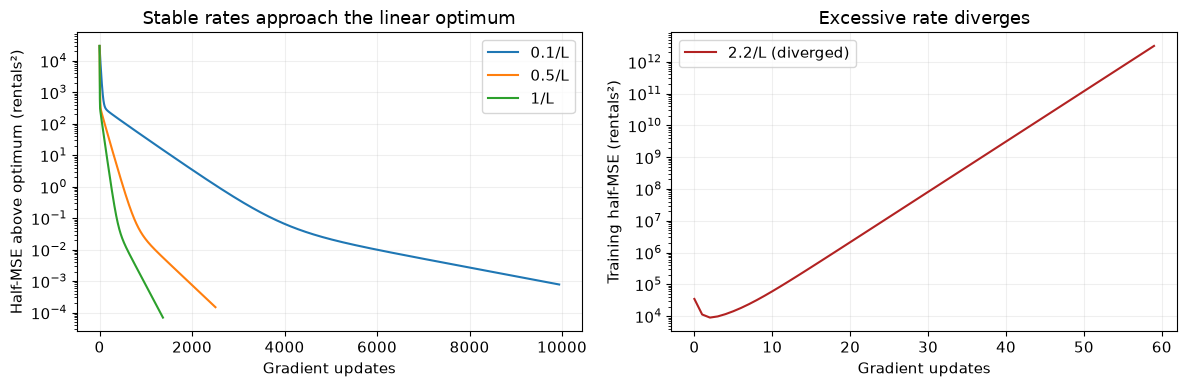

Finite-difference gradient check passed.
Training RMSE difference from least-squares optimum: 7.748022937903443e-06
Largest training prediction difference: 0.7534505581859889


In [6]:
reference_weights = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
reference_loss = float(np.mean((X_train @ reference_weights - y_train)**2) / 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run, factor in zip(runs, rate_factors):
    if run["status"] == "diverged":
        axes[1].plot(np.arange(len(run["loss_history"])), run["loss_history"], color="firebrick", label=f"{factor:g}/L (diverged)")
    else:
        excess_loss = np.maximum(run["loss_history"] - reference_loss, 1e-8)
        axes[0].plot(np.arange(len(excess_loss)), excess_loss, label=f"{factor:g}/L")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("Gradient updates")
    ax.legend()
axes[0].set(ylabel="Half-MSE above optimum (rentals²)", title="Stable rates approach the linear optimum")
axes[1].set(ylabel="Training half-MSE (rentals²)", title="Excessive rate diverges")
fig.tight_layout()
plt.show()

small_X, small_y = X_train[:64], y_train[:64]
probe = np.linspace(-0.1, 0.1, X_train.shape[1])
analytic = small_X.T @ (small_X @ probe - small_y) / len(small_y)
numeric = np.zeros_like(probe)
epsilon = 1e-4
for j in range(len(probe)):
    offset = np.zeros_like(probe)
    offset[j] = epsilon
    numeric[j] = (np.mean((small_X @ (probe + offset) - small_y)**2) - np.mean((small_X @ (probe - offset) - small_y)**2)) / (4 * epsilon)
assert np.allclose(analytic, numeric, rtol=1e-5, atol=1e-4)
prediction_gap = float(np.max(np.abs(X_train @ phase_one_weights - X_train @ reference_weights)))
gd_train_rmse = regression_metrics(y_train, X_train @ phase_one_weights)["RMSE"]
reference_rmse = regression_metrics(y_train, X_train @ reference_weights)["RMSE"]
assert abs(gd_train_rmse - reference_rmse) < 0.001
assert np.all(np.diff(best_run["loss_history"]) <= 1e-7)
assert np.isclose(best_run["loss_history"][-1], gd_train_rmse**2 / 2, rtol=1e-7)
print("Finite-difference gradient check passed.")
print("Training RMSE difference from least-squares optimum:", abs(gd_train_rmse-reference_rmse))
print("Largest training prediction difference:", prediction_gap)


### 7. Measure the model's errors
Report training and validation R²/RMSE. Compare with a model that always predicts the training mean. Plot predictions, errors and mean demand by hour. An error is `actual - predicted`, so positive errors mean underprediction. Count negative predictions without hiding them by clipping at this stage.

,model,partition,R2,RMSE
0,gradient descent,training,0.6937,100.2631
1,training-mean baseline,training,0.0000,181.1644
2,gradient descent,validation,0.6980,99.4649
3,training-mean baseline,validation,-0.0006,181.0340


Negative validation predictions: 202


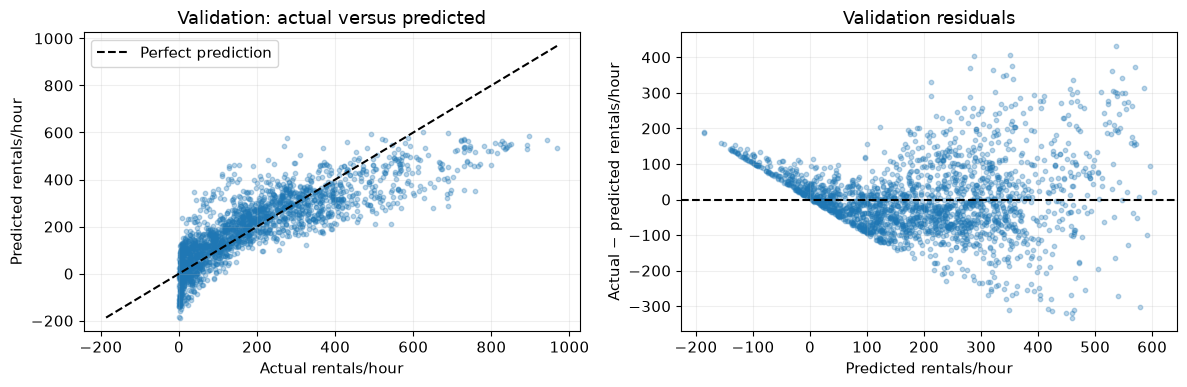

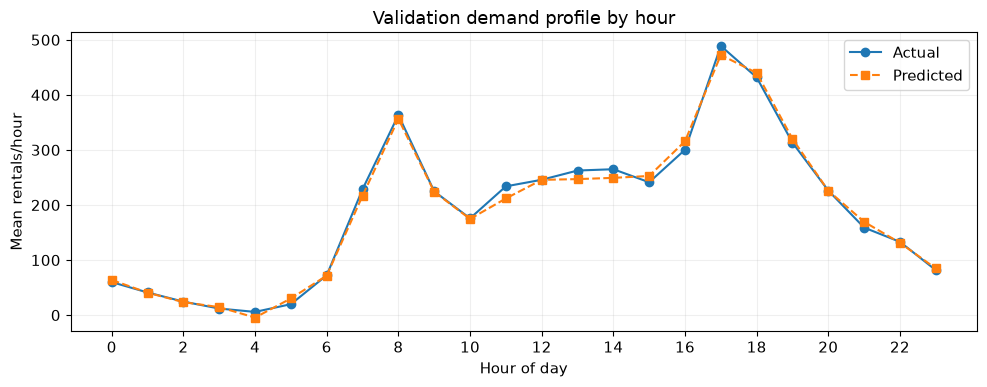

,feature,weight
0,intercept,190.69155
1,yr,43.94300
2,holiday,2.06136
3,workingday,5.33369
4,temp,15.10711
5,atemp,20.67371
6,hum,-15.64255
7,windspeed,-3.90086
8,day_of_month,1.72668
9,hr_1,-3.60831


In [7]:
train_predictions = X_train @ phase_one_weights
val_predictions = X_val @ phase_one_weights
metric_rows = []
for partition, actual, prediction in [("training", y_train, train_predictions), ("validation", y_val, val_predictions)]:
    metric_rows.append({"model": "gradient descent", "partition": partition, **regression_metrics(actual, prediction)})
    metric_rows.append({"model": "training-mean baseline", "partition": partition, **regression_metrics(actual, np.full(len(actual), y_train.mean()))})
metrics_table = pd.DataFrame(metric_rows)
display(metrics_table.round(4))
validation_metrics = regression_metrics(y_val, val_predictions)
residuals = y_val - val_predictions
print("Negative validation predictions:", int((val_predictions < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_val, val_predictions, s=10, alpha=0.3)
limits = [min(0, val_predictions.min()), max(y_val.max(), val_predictions.max())]
axes[0].plot(limits, limits, color="black", linestyle="--", label="Perfect prediction")
axes[0].set(xlabel="Actual rentals/hour", ylabel="Predicted rentals/hour", title="Validation: actual versus predicted")
axes[0].legend()
axes[1].scatter(val_predictions, residuals, s=10, alpha=0.3)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted rentals/hour", ylabel="Actual − predicted rentals/hour", title="Validation residuals")
fig.tight_layout()
plt.show()

hourly_validation = pd.DataFrame({"hour": val_df.hr.to_numpy(), "actual": y_val, "predicted": val_predictions}).groupby("hour").mean()
fig, ax = plt.subplots()
ax.plot(hourly_validation.index, hourly_validation.actual, marker="o", label="Actual")
ax.plot(hourly_validation.index, hourly_validation.predicted, marker="s", linestyle="--", label="Predicted")
ax.set(xlabel="Hour of day", ylabel="Mean rentals/hour", title="Validation demand profile by hour", xticks=range(0,24,2))
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame({"feature": weight_names, "weight": phase_one_weights}).round(5))


### 8. Save the result for Phase Two
Save the actual gradient-descent weights, their column order, optimizer settings, training-only preprocessing, split IDs and data hashes in `artifacts/phase_one.json`. Phase Two must use these fitted values.

In [8]:
phase_one_hyperparameters = {
    "learning_rate": best_run["learning_rate"], "max_iter": max_iter,
    "iterations": best_run["iterations"], "tolerance": tolerance, "patience": patience,
    "status": best_run["status"], "initialization": "zeros", "objective": "half_mse",
}
phase_one_artifact = {
    "phase": 1, "team_ids": ids, "seed": seed,
    "weights": phase_one_weights.tolist(), "weight_names": weight_names,
    "hyperparameters": phase_one_hyperparameters,
    "preprocessing": {"date_features": ["day_of_month"], "category_levels": category_levels,
                      "weather_mapping": {"4": 3},
                      "feature_names": feature_names, "means": feature_mean.to_dict(),
                      "scales": feature_scale.to_dict(), "constant_columns": constant_columns},
    "train_record_ids": train_df.instant.tolist(), "validation_record_ids": val_df.instant.tolist(),
    "training_metrics": regression_metrics(y_train, train_predictions), "validation_metrics": validation_metrics,
    "loss_history": best_run["loss_history"].tolist(),
    "learning_rate_search": json.loads(search_results.to_json(orient="records")),
    "source_sha256": {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
                      for name in ["train.csv", "test.csv", "sample_submission.csv"]},
}
artifact_dir = PROJECT_DIR / "artifacts"
artifact_dir.mkdir(exist_ok=True)
artifact_path = artifact_dir / "phase_one.json"
artifact_path.write_text(json.dumps(phase_one_artifact, indent=2), encoding="utf-8")
assert len(phase_one_weights) == len(weight_names)
print("Phase Two artifact saved:", artifact_path.relative_to(PROJECT_DIR))


Phase Two artifact saved: artifacts\phase_one.json


### Why we made these changes
The first encoder could not handle weather code 4 because training had no examples. Pooling codes 3 and 4 gives it a stated adverse-weather effect without using validation targets.

An initial elapsed-days feature almost repeated year, month and day-of-month. Gradient descent appeared to stop, but the optimum check showed unfinished learning. We removed that near-duplicate trend and kept the calendar inputs. This was a numerical stability choice, not proof that a time trend is useless.

Temperature and feels-like temperature remain together for now. Their training correlation is about 0.986; correlation alone does not tell us which to remove. Phase Four supplies model-based evidence.

### Results summary
The code below prints the measured values from this run. The final Outcome cell gives the short interpretation.

In [9]:
from IPython.display import Markdown
train_metrics = regression_metrics(y_train, train_predictions)
peak_hour = int(hourly_validation.actual.idxmax())
display(Markdown(
    f"Team seed **{seed}** produced **{len(train_df):,} training / {len(val_df):,} validation rows**. "
    f"Gradient descent **{best_run['status']}** after **{best_run['iterations']:,} updates**, "
    f"using learning rate **{best_run['learning_rate']:.6f}**. "
    f"Training R² **{train_metrics['R2']:.4f}**, RMSE **{train_metrics['RMSE']:.2f}**; "
    f"validation R² **{validation_metrics['R2']:.4f}**, RMSE **{validation_metrics['RMSE']:.2f} rentals/hour**. "
    f"The observed validation mean peaks at hour **{peak_hour}**. "
    f"There are **{int((val_predictions < 0).sum())} negative validation predictions**, an operational limitation of an unconstrained linear model. "
    "An unexpected input issue was severe weather appearing only in validation; fixed pooling of weather codes 3 and 4 prevents an unlearnable category coefficient. "
    "A nearly redundant elapsed-date trend also stalled optimization and was removed in favor of the existing calendar representation. "
    "The excessive learning rate provides a divergence comparison. The actual-versus-predicted plot shows underprediction at the high-demand end. A nontrivial residual spread remains even after convergence, "
    "consistent with the expectation that an additive linear baseline cannot capture all demand structure. "
    "Calendar and weather redundancy can make individual coefficients unstable even when predictions converge; "
    "model-backed feature verdicts are deferred to Phase Four. Phase Two receives the actual fitted weights and settings."
))


Team seed **29578** produced **8,708 training / 2,178 validation rows**. Gradient descent **converged** after **9,938 updates**, using learning rate **0.027631**. Training R² **0.6937**, RMSE **100.26**; validation R² **0.6980**, RMSE **99.46 rentals/hour**. The observed validation mean peaks at hour **17**. There are **202 negative validation predictions**, an operational limitation of an unconstrained linear model. An unexpected input issue was severe weather appearing only in validation; fixed pooling of weather codes 3 and 4 prevents an unlearnable category coefficient. A nearly redundant elapsed-date trend also stalled optimization and was removed in favor of the existing calendar representation. The excessive learning rate provides a divergence comparison. The actual-versus-predicted plot shows underprediction at the high-demand end. A nontrivial residual spread remains even after convergence, consistent with the expectation that an additive linear baseline cannot capture all demand structure. Calendar and weather redundancy can make individual coefficients unstable even when predictions converge; model-backed feature verdicts are deferred to Phase Four. Phase Two receives the actual fitted weights and settings.

### Optional bonus (+5%): the operator's cost

**Expectation, before this experiment:** charging more for missed demand should raise predictions on average and reduce underprediction. Ordinary RMSE may rise because the goal has changed.

We interpret the brief's cost as **weighted squared error**: for equal-sized errors, underprediction costs exactly three times overprediction. Let $e_i=x_i^T w-y_i$ and let $a_i=3$ when $e_i<0$, otherwise $a_i=1$. Then

$$J(w)=\frac{1}{2m}\sum_i a_i e_i^2,\qquad
\nabla J(w)=\frac{1}{m}X^T(a\odot e).$$

For $e_i<0$, the derivative with respect to the prediction is $3e_i$; for $e_i>0$, it is $e_i$. At zero both derivatives are zero, so the gradient exists there too. We recompute the weights from the current errors at every step. Holding them fixed would optimize the wrong loss.

Use the same training/validation rows, scaling and linear features as Phase One. Start from its MSE weights. The gradient has Lipschitz bound $3L$, so rate $1/(3L)$ is a safe fixed step. Stop when the largest absolute training-gradient entry is at most $10^{-5}$, with a 50,000-update cap. Validation does not control stopping. This is a separate operator-cost experiment; the required Phase Two still receives the original MSE weights.


,R2,RMSE,asymmetric_half_MSE,mean_prediction,underprediction_fraction,missed_rentals_per_hour,excess_rentals_per_hour
model,,,,,,,
MSE baseline,0.69795,99.46491,10750.60403,194.19155,0.44674,37.28337,36.37207
Asymmetric 3:1,0.63881,108.76675,8595.37750,236.40806,0.30762,21.30076,62.60598


Bonus convergence: converged updates: 4338 gradient max: 9.987157688456332e-06
Finite-difference gradient error: 1.6442004202588123e-08
Validation cost reduction: 20.05%; mean prediction shift: +42.22


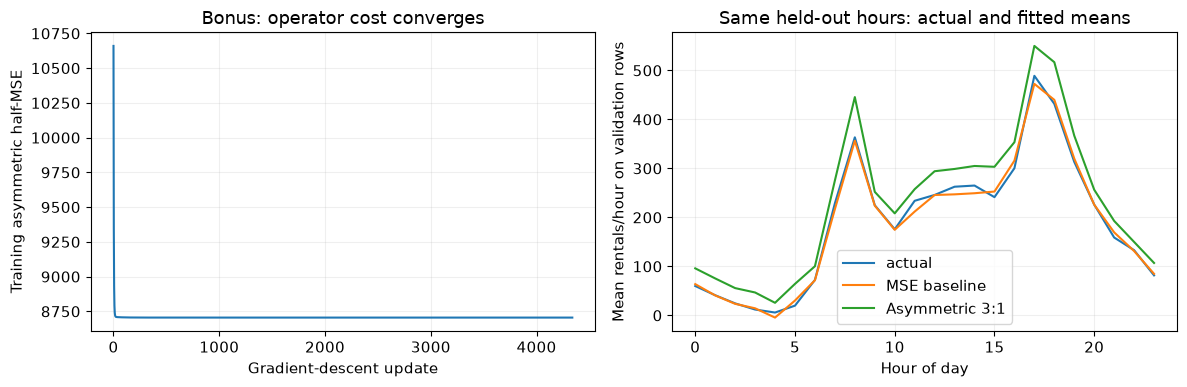

**Bonus outcome:** validation operator cost falls **20.05%**; mean prediction rises **42.22 rentals/hour**. RMSE changes from **99.46** to **108.77**. This trades ordinary squared-error accuracy for fewer missed rentals. It does not establish future-date robustness or a monetary saving.

In [10]:
from threadpoolctl import threadpool_limits

def asymmetric_loss_gradient(X, y, weights, under_weight=3.0):
    error = X @ weights - y
    cost_weight = np.where(error < 0, under_weight, 1.0)
    loss = float(np.mean(cost_weight * error ** 2) / 2)
    gradient = X.T @ (cost_weight * error) / len(y)
    return loss, gradient

def asymmetric_gradient_descent(X, y, initial_weights, learning_rate,
                                max_iter=50000, gradient_tol=1e-5):
    weights = np.array(initial_weights, dtype=float, copy=True)
    loss, gradient = asymmetric_loss_gradient(X, y, weights)
    loss_history = [loss]
    status = "max_iter"
    for iteration in range(1, max_iter + 1):
        weights -= learning_rate * gradient
        new_loss, gradient = asymmetric_loss_gradient(X, y, weights)
        assert np.isfinite(new_loss) and new_loss <= loss + 1e-8, "Unstable bonus update"
        loss = new_loss
        loss_history.append(loss)
        if np.max(np.abs(gradient)) <= gradient_tol:
            status = "converged"
            break
    return {"weights": weights, "loss_history": np.array(loss_history),
            "iterations": iteration, "status": status,
            "gradient_inf": float(np.max(np.abs(gradient))),
            "learning_rate": learning_rate, "gradient_tol": gradient_tol,
            "max_iter": max_iter}

# Finite differences check all coefficients, including the intercept.
bonus_probe = phase_one_weights.copy()
bonus_eps = 1e-4
_, bonus_analytic_gradient = asymmetric_loss_gradient(X_train, y_train, bonus_probe)
bonus_numeric_gradient = np.empty_like(bonus_probe)
for bonus_j in range(len(bonus_probe)):
    bonus_delta = np.zeros_like(bonus_probe)
    bonus_delta[bonus_j] = bonus_eps
    bonus_plus = asymmetric_loss_gradient(X_train, y_train, bonus_probe + bonus_delta)[0]
    bonus_minus = asymmetric_loss_gradient(X_train, y_train, bonus_probe - bonus_delta)[0]
    bonus_numeric_gradient[bonus_j] = (bonus_plus - bonus_minus) / (2 * bonus_eps)
bonus_gradient_error = float(np.max(np.abs(bonus_numeric_gradient - bonus_analytic_gradient)))
assert bonus_gradient_error < 1e-5

bonus_L = float(np.linalg.eigvalsh(X_train.T @ X_train / len(y_train)).max())
# A single BLAS thread avoids scheduling overhead for these small matrix products.
with threadpool_limits(limits=1, user_api="blas"):
    bonus_run = asymmetric_gradient_descent(X_train, y_train, phase_one_weights, 1 / (3 * bonus_L))
assert bonus_run["status"] == "converged", "Do not report an unconverged bonus model"

bonus_predictions = {"MSE baseline": X_val @ phase_one_weights,
                     "Asymmetric 3:1": X_val @ bonus_run["weights"]}
bonus_rows = []
for bonus_name, bonus_pred in bonus_predictions.items():
    bonus_error = bonus_pred - y_val
    bonus_rows.append({"model": bonus_name,
        **regression_metrics(y_val, bonus_pred),
        "asymmetric_half_MSE": float(np.mean(np.where(bonus_error < 0, 3., 1.) * bonus_error ** 2) / 2),
        "mean_prediction": float(bonus_pred.mean()),
        "underprediction_fraction": float(np.mean(bonus_error < 0)),
        "missed_rentals_per_hour": float(np.maximum(-bonus_error, 0).mean()),
        "excess_rentals_per_hour": float(np.maximum(bonus_error, 0).mean())})
bonus_comparison = pd.DataFrame(bonus_rows).set_index("model")
bonus_cost_reduction_pct = float(100 * (1 - bonus_comparison.loc["Asymmetric 3:1", "asymmetric_half_MSE"]
                                      / bonus_comparison.loc["MSE baseline", "asymmetric_half_MSE"]))
bonus_mean_shift = float((bonus_predictions["Asymmetric 3:1"] - bonus_predictions["MSE baseline"]).mean())
display(bonus_comparison.round(5))
print("Bonus convergence:", bonus_run["status"], "updates:", bonus_run["iterations"],
      "gradient max:", bonus_run["gradient_inf"])
print("Finite-difference gradient error:", bonus_gradient_error)
print(f"Validation cost reduction: {bonus_cost_reduction_pct:.2f}%; mean prediction shift: {bonus_mean_shift:+.2f}")

bonus_figure, bonus_axes = plt.subplots(1, 2, figsize=(12, 4))
bonus_axes[0].plot(bonus_run["loss_history"])
bonus_axes[0].set(xlabel="Gradient-descent update", ylabel="Training asymmetric half-MSE",
                  title="Bonus: operator cost converges")
bonus_hourly = pd.DataFrame({"hour": val_df.hr.to_numpy(), "actual": y_val,
                            **bonus_predictions}).groupby("hour").mean()
bonus_hourly.plot(ax=bonus_axes[1])
bonus_axes[1].set(xlabel="Hour of day", ylabel="Mean rentals/hour on validation rows",
                  title="Same held-out hours: actual and fitted means")
bonus_figure.tight_layout()
plt.show()

bonus_artifact = {
    "experiment": "Optional Phase One bonus", "seed": seed, "team_ids": ids,
    "loss": "mean(a * (prediction - actual)^2) / 2; a=3 below actual, otherwise 1",
    "gradient": "X.T @ (a * (X @ weights - y)) / m; recompute a each update",
    "interpretation": "3:1 weighted squared error, not a 3:1 linear error penalty",
    "phase_one_sha256": hashlib.sha256(artifact_path.read_bytes()).hexdigest(),
    "source_sha256": phase_one_artifact["source_sha256"],
    "preprocessing": phase_one_artifact["preprocessing"],
    "weight_names": weight_names, "weights": bonus_run["weights"].tolist(),
    "initial_weights": phase_one_weights.tolist(),
    "train_record_ids": train_df.instant.tolist(), "validation_record_ids": val_df.instant.tolist(),
    "optimizer": {key: bonus_run[key] for key in ["iterations", "status", "gradient_inf",
                  "learning_rate", "gradient_tol", "max_iter"]},
    "loss_history": bonus_run["loss_history"].tolist(),
    "gradient_finite_difference_max_error": bonus_gradient_error,
    "validation_comparison": bonus_comparison.reset_index().to_dict(orient="records"),
    "validation_cost_reduction_percent": bonus_cost_reduction_pct,
    "validation_mean_prediction_shift": bonus_mean_shift,
    "fraction_validation_predictions_increased": float(np.mean(
        bonus_predictions["Asymmetric 3:1"] > bonus_predictions["MSE baseline"])),
    "main_phase_chain_changed": False,
    "limitations": "Same tuned validation split; operator-cost units are squared rentals, not measured currency. Raw predictions for both models; no clipping."
}
(artifact_dir / "bonus_asymmetric.json").write_text(json.dumps(bonus_artifact, indent=2), encoding="utf-8")
display(Markdown(
    f"**Bonus outcome:** validation operator cost falls **{bonus_cost_reduction_pct:.2f}%**; "
    f"mean prediction rises **{bonus_mean_shift:.2f} rentals/hour**. "
    f"RMSE changes from **{bonus_comparison.loc['MSE baseline', 'RMSE']:.2f}** to "
    f"**{bonus_comparison.loc['Asymmetric 3:1', 'RMSE']:.2f}**. "
    "This trades ordinary squared-error accuracy for fewer missed rentals. "
    "It does not establish future-date robustness or a monetary saving."))


### Outcome
The seed is **29578**. The chosen linear model gives validation **R² 0.6980** and **RMSE 99.46 rentals/hour**. It converged after **9,938** updates at rate **0.02763121**.

It captures daily peaks but still makes negative predictions and misses some high-demand counts. Two initial issues were less obvious: a rare weather category absent from training and a near-duplicate date trend. The checks found both. The saved weights and settings are the input to Phase Two.

## Phase Two: polynomial regression

**Goal:** Add curved weather effects using Phase One’s actual weights.

### Expectation

*Kept from the phase’s first run.*

Before running: squared and cubic weather terms may capture curvature that the additive linear model misses, so training error should decrease. Validation improvement may be modest because this basis still has no hour-by-workingday interactions. Higher powers can worsen conditioning and require more updates. We will compare degree 1, 2 and 3 on the same validation rows, not assume the largest degree wins.

### 1. Read Phase One's result
Check the seed, IDs, file hashes and feature order. Copy Phase One's fitted weights. Keep its original linear columns unchanged. Newly added coefficients start at zero, so the expanded model must initially make the same predictions.

In [11]:
phase_one_path = artifact_dir / "phase_one.json"
phase_one_input = json.loads(phase_one_path.read_text(encoding="utf-8"))
assert phase_one_input["seed"] == seed
assert phase_one_input["weight_names"] == weight_names
assert phase_one_input["train_record_ids"] == train_df.instant.tolist()
assert phase_one_input["validation_record_ids"] == val_df.instant.tolist()
for filename, digest in phase_one_input["source_sha256"].items():
    assert hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest() == digest
phase_two_base_weights = np.asarray(phase_one_input["weights"], dtype=float)
assert np.allclose(phase_two_base_weights, phase_one_weights)
phase_one_optimizer_settings = phase_one_input["hyperparameters"].copy()
print("Consumed Phase One weights:", len(phase_two_base_weights))
print("Previous optimizer settings:", phase_one_optimizer_settings)


Consumed Phase One weights: 54
Previous optimizer settings: {'learning_rate': 0.027631211226832285, 'max_iter': 12000, 'iterations': 9938, 'tolerance': 1e-10, 'patience': 20, 'status': 'converged', 'initialization': 'zeros', 'objective': 'half_mse'}


### 2. Add selected polynomial terms
Compare degrees 2 and 3. Add squares, then cubes, of `temp`, `hum` and `windspeed`. Keep the linear `atemp` feature, but do not also expand it because it closely overlaps with temperature. Powers of a one-hot indicator would just repeat the indicator.

This is a selected additive polynomial model: it has individual powers, not interactions between different columns. Build powers from the already-standardized inputs, then scale each new term using training statistics only. The old columns keep their original meaning.

In [12]:
phase_two_expand_features = ["temp", "hum", "windspeed"]
phase_two_degrees = [2, 3]

def polynomial_design(degree):
    term_names, train_terms, val_terms = [], [], []
    for power in range(2, degree + 1):
        for feature in phase_two_expand_features:
            column = weight_names.index(feature)
            term_names.append(f"{feature}^{power}")
            train_terms.append(X_train[:, column] ** power)
            val_terms.append(X_val[:, column] ** power)
    train_raw = np.column_stack(train_terms)
    val_raw = np.column_stack(val_terms)
    means = train_raw.mean(axis=0)
    scales = train_raw.std(axis=0)
    assert (scales > 0).all()
    train_design = np.column_stack([X_train, (train_raw - means) / scales])
    val_design = np.column_stack([X_val, (val_raw - means) / scales])
    names = weight_names + term_names
    initial = np.concatenate([phase_two_base_weights, np.zeros(len(term_names))])
    assert np.allclose(train_design @ initial, X_train @ phase_two_base_weights)
    assert np.allclose(val_design @ initial, X_val @ phase_two_base_weights)
    assert np.isfinite(train_design).all() and np.isfinite(val_design).all()
    return {"train": train_design, "validation": val_design, "names": names,
            "term_names": term_names, "term_means": means, "term_scales": scales,
            "initial_weights": initial}

phase_two_designs = {degree: polynomial_design(degree) for degree in phase_two_degrees}
print("Expanded matrix dimensions:", {d: b["train"].shape for d, b in phase_two_designs.items()})
print("Warm-start predictions exactly match the Phase One baseline within floating-point tolerance.")


Expanded matrix dimensions: {2: (8708, 57), 3: (8708, 60)}
Warm-start predictions exactly match the Phase One baseline within floating-point tolerance.


### 3. Train with the same gradient descent
Start every candidate from Phase One's weights plus zeros. Try its old rate and `0.5/L`, `1/L` for the expanded training matrix, keeping only stable rates below `2/L`.

Use tolerance `1e-12`, patience 20 and a 100,000-update limit because correlated powers can take longer to fit. Check training RMSE against the reference optimum within 0.001. Choose degree and rate using validation RMSE, not the hidden test file.

In [13]:
phase_two_tolerance = 1e-12
phase_two_max_iter = 100000
phase_two_patience = phase_one_optimizer_settings["patience"]
phase_two_runs = []
phase_two_rows = []
for degree, basis in phase_two_designs.items():
    design = basis["train"]
    largest_eigenvalue = float(np.linalg.eigvalsh(design.T @ design / len(y_train)).max())
    candidate_rates = sorted(set([phase_one_optimizer_settings["learning_rate"],
                                  0.5 / largest_eigenvalue, 1.0 / largest_eigenvalue]))
    diagnostic_weights = np.linalg.lstsq(design, y_train, rcond=None)[0]
    diagnostic_rmse = regression_metrics(y_train, design @ diagnostic_weights)["RMSE"]
    for rate in candidate_rates:
        if not 0 < rate < 2 / largest_eigenvalue:
            print("Skipping unstable inherited rate", degree, rate)
            continue
        result = gradient_descent(design, y_train, rate, phase_two_max_iter,
                                  phase_two_tolerance, phase_two_patience,
                                  initial_weights=basis["initial_weights"])
        train_scores = regression_metrics(y_train, design @ result["weights"])
        val_scores = regression_metrics(y_val, basis["validation"] @ result["weights"])
        optimum_gap = abs(train_scores["RMSE"] - diagnostic_rmse)
        verified = result["status"] == "converged" and optimum_gap < 0.001
        assert np.isclose(result["loss_history"][0], phase_one_input["training_metrics"]["RMSE"]**2 / 2)
        assert np.isclose(result["loss_history"][-1], train_scores["RMSE"]**2 / 2, rtol=1e-6)
        phase_two_rows.append({"degree": degree, "learning_rate": rate,
                               "iterations": result["iterations"], "status": result["status"],
                               "verified": verified, "train_R2": train_scores["R2"],
                               "train_RMSE": train_scores["RMSE"], "validation_R2": val_scores["R2"],
                               "validation_RMSE": val_scores["RMSE"], "optimum_RMSE_gap": optimum_gap})
        phase_two_runs.append({"degree": degree, "run": result, "reference_loss": diagnostic_rmse**2/2})
phase_two_search = pd.DataFrame(phase_two_rows)
display(phase_two_search.round(6))
eligible_polynomials = phase_two_search[phase_two_search.verified]
assert len(eligible_polynomials), "No polynomial fit passed convergence checks; revise numerical settings."
phase_two_best_index = eligible_polynomials.sort_values(["validation_RMSE", "degree", "iterations"]).index[0]
phase_two_best = phase_two_runs[phase_two_best_index]
phase_two_degree = phase_two_best["degree"]
phase_two_model = phase_two_best["run"]
phase_two_basis = phase_two_designs[phase_two_degree]
phase_two_weights = phase_two_model["weights"].copy()
assert np.array_equal(phase_two_base_weights, np.asarray(phase_one_input["weights"]))


,degree,learning_rate,iterations,status,verified,train_R2,train_RMSE,validation_R2,validation_RMSE,optimum_RMSE_gap
0,2,0.027631,15238,converged,True,0.695991,99.888562,0.699667,99.182024,0.0
1,2,0.136563,3621,converged,True,0.695991,99.888562,0.699666,99.182066,0.0
2,2,0.273126,1933,converged,True,0.695991,99.888562,0.699666,99.182077,0.0
3,3,0.027631,20294,converged,True,0.700358,99.168644,0.703750,98.505455,0.0
4,3,0.116685,5399,converged,True,0.700358,99.168644,0.703750,98.505398,0.0
5,3,0.233371,2848,converged,True,0.700358,99.168644,0.703751,98.505381,0.0


### 4. Compare degrees and errors
Show each degree's training/validation R² and RMSE beside Phase One's result. Plot optimization progress and prediction errors. Report raw predictions, including any negative values, consistently with Phase One. The larger bias–variance study comes in Phase Three.

,degree,features,train_R2,train_RMSE,validation_R2,validation_RMSE
0,1,53,0.69371,100.26311,0.69795,99.46491
1,2,56,0.69599,99.88856,0.69967,99.18202
2,3,59,0.70036,99.16864,0.70375,98.50538


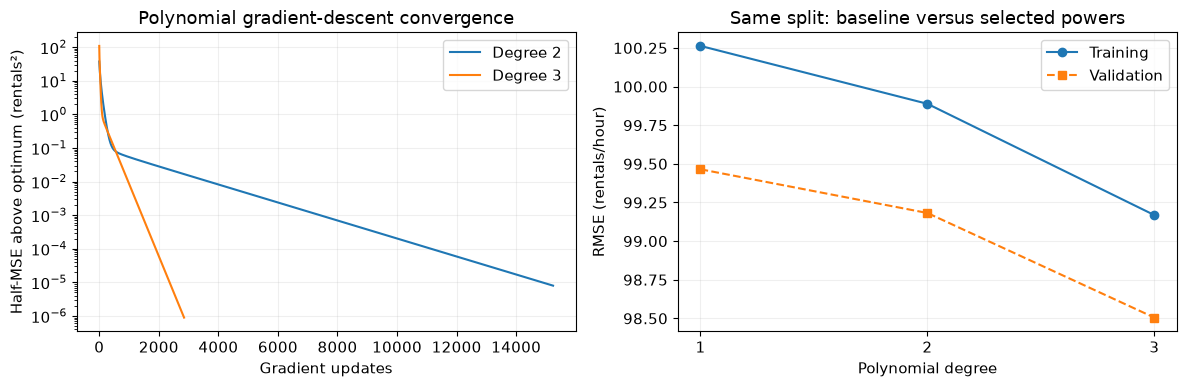

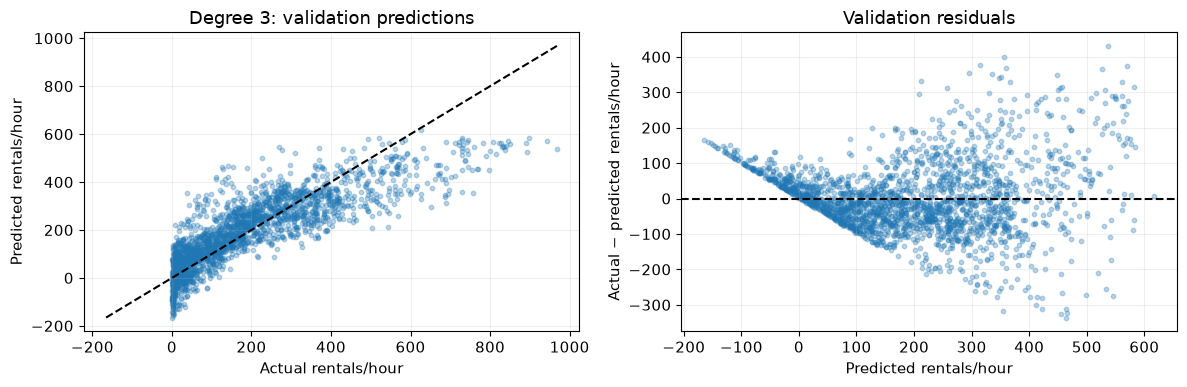

,feature,weight
54,temp^2,9.995184
55,hum^2,-1.405649
56,windspeed^2,-2.171903
57,temp^3,-25.014531
58,hum^3,6.304468
59,windspeed^3,-2.720931


Negative validation predictions: 209


In [14]:
phase_two_comparison_rows = [{"degree": 1, "features": len(weight_names)-1,
    "train_R2": phase_one_input["training_metrics"]["R2"], "train_RMSE": phase_one_input["training_metrics"]["RMSE"],
    "validation_R2": phase_one_input["validation_metrics"]["R2"], "validation_RMSE": phase_one_input["validation_metrics"]["RMSE"]}]
phase_two_degree_indices = []
for degree in phase_two_degrees:
    verified_rows = eligible_polynomials[eligible_polynomials.degree == degree]
    assert len(verified_rows), f"Degree {degree} has no verified fit"
    index = verified_rows.sort_values(["validation_RMSE", "iterations"]).index[0]
    phase_two_degree_indices.append(index)
    row = phase_two_search.loc[index]
    phase_two_comparison_rows.append({"degree": degree, "features": len(phase_two_designs[degree]["names"])-1,
        **{key: float(row[key]) for key in ["train_R2", "train_RMSE", "validation_R2", "validation_RMSE"]}})
phase_two_comparison = pd.DataFrame(phase_two_comparison_rows)
display(phase_two_comparison.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for index in phase_two_degree_indices:
    entry = phase_two_runs[index]
    loss = np.maximum(entry["run"]["loss_history"] - entry["reference_loss"], 1e-9)
    axes[0].plot(np.arange(len(loss)), loss, label=f"Degree {entry['degree']}")
axes[0].set_yscale("log")
axes[0].set(xlabel="Gradient updates", ylabel="Half-MSE above optimum (rentals²)", title="Polynomial gradient-descent convergence")
axes[0].legend()
axes[1].plot(phase_two_comparison.degree, phase_two_comparison.train_RMSE, marker="o", label="Training")
axes[1].plot(phase_two_comparison.degree, phase_two_comparison.validation_RMSE, marker="s", linestyle="--", label="Validation")
axes[1].set(xlabel="Polynomial degree", ylabel="RMSE (rentals/hour)", title="Same split: baseline versus selected powers", xticks=[1,2,3])
axes[1].legend()
fig.tight_layout()
plt.show()

phase_two_val_predictions = phase_two_basis["validation"] @ phase_two_weights
phase_two_train_predictions = phase_two_basis["train"] @ phase_two_weights
phase_two_val_metrics = regression_metrics(y_val, phase_two_val_predictions)
phase_two_train_metrics = regression_metrics(y_train, phase_two_train_predictions)
phase_two_negative_count = int((phase_two_val_predictions < 0).sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_val, phase_two_val_predictions, s=10, alpha=0.3)
limits = [min(0, phase_two_val_predictions.min()), max(y_val.max(), phase_two_val_predictions.max())]
axes[0].plot(limits, limits, color="black", linestyle="--")
axes[0].set(xlabel="Actual rentals/hour", ylabel="Predicted rentals/hour", title=f"Degree {phase_two_degree}: validation predictions")
axes[1].scatter(phase_two_val_predictions, y_val-phase_two_val_predictions, s=10, alpha=0.3)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted rentals/hour", ylabel="Actual − predicted rentals/hour", title="Validation residuals")
fig.tight_layout()
plt.show()
display(pd.DataFrame({"feature": phase_two_basis["names"], "weight": phase_two_weights}).tail(len(phase_two_basis["term_names"])).round(6))
print("Negative validation predictions:", phase_two_negative_count)


### 5. Save the result for Phase Three
Save the chosen degree, expanded term names, fitted weights, scaling and scores in `artifacts/phase_two.json`. These are the real fitted values used by the next phase.

In [15]:
phase_two_artifact = {
    "phase": 2, "seed": seed, "degree": int(phase_two_degree),
    "basis": "individual powers only; no interaction terms", "expanded_features": phase_two_expand_features,
    "weight_names": phase_two_basis["names"], "weights": phase_two_weights.tolist(),
    "initial_weights": phase_two_basis["initial_weights"].tolist(),
    "phase_one_input_sha256": hashlib.sha256(phase_one_path.read_bytes()).hexdigest(),
    "phase_one_hyperparameters": phase_one_optimizer_settings,
    "preprocessing": {"base": phase_one_input["preprocessing"],
        "new_term_names": phase_two_basis["term_names"], "new_term_means": phase_two_basis["term_means"].tolist(),
        "new_term_scales": phase_two_basis["term_scales"].tolist(),
        "power_input": "Phase One standardized continuous columns"},
    "hyperparameters": {"learning_rate": phase_two_model["learning_rate"],
        "iterations": phase_two_model["iterations"], "max_iter": phase_two_max_iter,
        "tolerance": phase_two_tolerance, "patience": phase_two_patience,
        "status": phase_two_model["status"], "initialization": "Phase One weights plus zeros", "objective": "half_mse"},
    "train_record_ids": phase_one_input["train_record_ids"], "validation_record_ids": phase_one_input["validation_record_ids"],
    "source_sha256": phase_one_input["source_sha256"],
    "training_metrics": phase_two_train_metrics, "validation_metrics": phase_two_val_metrics,
    "search_results": json.loads(phase_two_search.to_json(orient="records")),
    "degree_comparison": json.loads(phase_two_comparison.to_json(orient="records")),
    "loss_history": phase_two_model["loss_history"].tolist(),
}
phase_two_artifact_path = artifact_dir / "phase_two.json"
phase_two_artifact_path.write_text(json.dumps(phase_two_artifact, indent=2), encoding="utf-8")
print("Saved:", phase_two_artifact_path.relative_to(PROJECT_DIR))


Saved: artifacts\phase_two.json


### Results summary
The output below compares the selected polynomial model with Phase One. A lower validation RMSE is useful, but does not prove better performance on later dates.

In [16]:
phase_two_rmse_gain = phase_one_input["validation_metrics"]["RMSE"] - phase_two_val_metrics["RMSE"]
phase_two_recommended_degree = int(phase_two_degree if phase_two_rmse_gain > 0 else 1)
display(Markdown(
    f"The selected polynomial degree is **{phase_two_degree}**, adding **{len(phase_two_basis['term_names'])} terms**. "
    f"It converged after **{phase_two_model['iterations']:,} updates** at learning rate **{phase_two_model['learning_rate']:.8f}**. "
    f"Training R² **{phase_two_train_metrics['R2']:.4f}**, RMSE **{phase_two_train_metrics['RMSE']:.2f}**; "
    f"validation R² **{phase_two_val_metrics['R2']:.4f}**, RMSE **{phase_two_val_metrics['RMSE']:.2f} rentals/hour**. "
    f"Validation RMSE reduction relative to Phase One is **{phase_two_rmse_gain:.4f} rentals/hour** "
    f"(negative means worse). The overall validation recommendation among degrees 1–3 is **degree {phase_two_recommended_degree}**. "
    f"The selected polynomial produces **{phase_two_negative_count} negative validation predictions**. "
    "Training-only term scaling and exact warm-start checks preserve pipeline integrity. "
    "Inspect the residual plots before claiming that polynomial curvature resolves the remaining demand structure. "
    "Phase Three receives the selected polynomial degree and basis for its required diagnosis; no bias–variance verdict is asserted here."
))


The selected polynomial degree is **3**, adding **6 terms**. It converged after **2,848 updates** at learning rate **0.23337059**. Training R² **0.7004**, RMSE **99.17**; validation R² **0.7038**, RMSE **98.51 rentals/hour**. Validation RMSE reduction relative to Phase One is **0.9595 rentals/hour** (negative means worse). The overall validation recommendation among degrees 1–3 is **degree 3**. The selected polynomial produces **209 negative validation predictions**. Training-only term scaling and exact warm-start checks preserve pipeline integrity. Inspect the residual plots before claiming that polynomial curvature resolves the remaining demand structure. Phase Three receives the selected polynomial degree and basis for its required diagnosis; no bias–variance verdict is asserted here.

### Outcome
Degree **3** wins the Phase Two comparison: validation **R² 0.7038**, **RMSE 98.51**. Its learning rate is **0.23337059**, with **2,848** updates.

The weather powers help, but the improvement is modest rather than a complete fix. Prediction errors remain at high demand. The exact degree, terms and fitted weights are saved for Phase Three.

## Phase Three: bias–variance and later-date validation

**Goal:** Check model complexity and performance on later dates.

### Expectation

*Kept from the phase’s first run.*

Before running: extending the degree-3 selective weather basis through degrees 1–5 should lower training error, but validation improvement may flatten or reverse. Similar training and random-validation errors would argue against strong random-split overfitting; persistent errors may reflect limitations of the additive basis. A latest-date holdout may be harder because it tests a different period rather than mixed hours from familiar dates. Its result could therefore change the practical generalization diagnosis.

### 1. Use Phase Two's choice and compare model sizes
Phase Two chose degree 3. Keep its three weather inputs and compare degrees **1–5** around that choice. Do not add a different feature family. Keep the seeded split unchanged.

Use our gradient descent at `1/L`, tolerance `1e-12` and patience 20. Allow up to 500,000 steps for the larger powers, but check the actual iteration counts. Every fit must agree with its reference training RMSE within 0.001 before we interpret its errors. Degree 3 and larger models continue from Phase Two's fitted weights; added terms start at zero.

In [17]:
phase_three_input_path = artifact_dir / "phase_two.json"
phase_three_input = json.loads(phase_three_input_path.read_text(encoding="utf-8"))
assert phase_three_input["seed"] == seed
assert phase_three_input["train_record_ids"] == train_df.instant.tolist()
assert phase_three_input["validation_record_ids"] == val_df.instant.tolist()
assert phase_three_input["phase_one_input_sha256"] == hashlib.sha256(phase_one_path.read_bytes()).hexdigest()
for name, digest in phase_three_input["source_sha256"].items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == digest
phase_three_anchor = int(phase_three_input["degree"])
phase_three_features = phase_three_input["expanded_features"]
assert phase_three_anchor == phase_two_degree
assert phase_three_features == phase_two_expand_features
phase_three_degrees = list(range(max(1, phase_three_anchor-2), phase_three_anchor+3))
phase_three_settings = {"max_iter": 500000, "tol": 1e-12, "patience": 20}

def phase_three_fit(train_matrix, validation_matrix, train_target, validation_target, initial):
    L_local = float(np.linalg.eigvalsh(train_matrix.T @ train_matrix / len(train_target)).max())
    result = gradient_descent(train_matrix, train_target, 1/L_local,
                              initial_weights=initial, **phase_three_settings)
    fitted_train = train_matrix @ result["weights"]
    fitted_validation = validation_matrix @ result["weights"]
    train_score = regression_metrics(train_target, fitted_train)
    validation_score = regression_metrics(validation_target, fitted_validation)
    reference = np.linalg.lstsq(train_matrix, train_target, rcond=None)[0]
    gap = abs(train_score["RMSE"]-regression_metrics(train_target, train_matrix @ reference)["RMSE"])
    assert result["status"] != "diverged"
    assert gap < 0.001, f"Optimization error {gap} is too large to diagnose model complexity"
    assert np.isclose(result["loss_history"][-1],train_score["RMSE"]**2/2,rtol=1e-6)
    return {"run":result,"train_predictions":fitted_train,"validation_predictions":fitted_validation,
            "train_metrics":train_score,"validation_metrics":validation_score,"optimum_gap":gap}

phase_three_random = {}
phase_three_rows = []
for degree in phase_three_degrees:
    if degree == 1:
        basis = {"train":X_train,"validation":X_val,"names":weight_names,
                 "initial_weights":phase_two_base_weights.copy()}
    else:
        basis = polynomial_design(degree)
        # Continue the actual Phase Two vector in its unchanged column order.
        if degree >= phase_three_anchor:
            inherited = np.asarray(phase_three_input["weights"])
            assert basis["names"][:len(inherited)] == phase_three_input["weight_names"]
            basis["initial_weights"] = np.concatenate([inherited,np.zeros(len(basis["names"])-len(inherited))])
    result = phase_three_fit(basis["train"],basis["validation"],y_train,y_val,basis["initial_weights"])
    phase_three_random[degree] = {"basis":basis,**result}
    phase_three_rows.append({"split":"seeded random","degree":degree,"predictors":len(basis["names"])-1,
        "train_R2":result["train_metrics"]["R2"],"train_RMSE":result["train_metrics"]["RMSE"],
        "validation_R2":result["validation_metrics"]["R2"],"validation_RMSE":result["validation_metrics"]["RMSE"],
        "RMSE_gap":result["validation_metrics"]["RMSE"]-result["train_metrics"]["RMSE"],
        "iterations":result["run"]["iterations"],"status":result["run"]["status"],"optimum_RMSE_gap":result["optimum_gap"]})
phase_three_random_table = pd.DataFrame(phase_three_rows)
display(phase_three_random_table.round(6))


,split,degree,predictors,train_R2,train_RMSE,validation_R2,validation_RMSE,RMSE_gap,iterations,status,optimum_RMSE_gap
0,seeded random,1,53,0.693707,100.263104,0.697948,99.465451,-0.797654,1098,converged,0.0
1,seeded random,2,56,0.695991,99.888562,0.699666,99.182077,-0.706485,1933,converged,0.0
2,seeded random,3,59,0.700358,99.168644,0.703751,98.505379,-0.663265,20,converged,0.0
3,seeded random,4,62,0.701492,98.980767,0.704710,98.345803,-0.634963,2471,converged,0.0
4,seeded random,5,65,0.701798,98.929940,0.704503,98.380260,-0.549680,10386,converged,0.0


### 2. Test one later-date split
Sort labeled rows by date and hour. Take the date at the 80% row boundary as the cutoff, keeping the whole date in validation. This rule uses dates only, not scores. Train on earlier dates and validate on later dates; do not shuffle or use a seed.

Fit the category levels, scaling and powers again using only the earlier training rows. Start these weights at zero: random-split weights have already seen some later dates. Compare all degrees on this **same single chronological split**. Separate local preprocessing keeps earlier phases unchanged.

In [18]:
phase_three_sorted = train_all.assign(_date=pd.to_datetime(train_all.dteday)).sort_values(["_date","hr"])
phase_three_cutoff = phase_three_sorted.iloc[int(0.8*len(phase_three_sorted))]["_date"]
chrono_train = phase_three_sorted.loc[phase_three_sorted._date < phase_three_cutoff].drop(columns="_date").copy()
chrono_val = phase_three_sorted.loc[phase_three_sorted._date >= phase_three_cutoff].drop(columns="_date").copy()
assert len(chrono_train)+len(chrono_val)==len(train_all)
assert pd.to_datetime(chrono_train.dteday).max() < pd.to_datetime(chrono_val.dteday).min()
assert set(chrono_train.instant).isdisjoint(chrono_val.instant)
assert set(chrono_train.dteday).isdisjoint(chrono_val.dteday)
chrono_y_train = chrono_train.cnt.to_numpy(dtype=float)
chrono_y_val = chrono_val.cnt.to_numpy(dtype=float)
chrono_levels = {c:sorted(categorical_values(chrono_train,c).unique().tolist()) for c in categorical_columns}

def chrono_encode(frame):
    numeric = frame[["yr","holiday","workingday","temp","atemp","hum","windspeed"]].astype(float).copy()
    numeric["day_of_month"] = pd.to_datetime(frame.dteday).dt.day.astype(float)
    for column,levels in chrono_levels.items():
        values=categorical_values(frame,column)
        assert set(values.unique()).issubset(levels), f"Chronological unseen category: {column}"
        for level in levels[1:]:
            numeric[f"{column}_{level}"]=(values==level).astype(float)
    return numeric

chrono_encoded_train,chrono_encoded_val = chrono_encode(chrono_train),chrono_encode(chrono_val)
chrono_scales_all=chrono_encoded_train.std(ddof=0)
chrono_feature_names=chrono_scales_all.index[chrono_scales_all>0].tolist()
chrono_means=chrono_encoded_train[chrono_feature_names].mean()
chrono_scales=chrono_scales_all[chrono_feature_names]
chrono_X_train=np.column_stack([np.ones(len(chrono_train)),((chrono_encoded_train[chrono_feature_names]-chrono_means)/chrono_scales).to_numpy()])
chrono_X_val=np.column_stack([np.ones(len(chrono_val)),((chrono_encoded_val[chrono_feature_names]-chrono_means)/chrono_scales).to_numpy()])
chrono_weight_names=["intercept"]+chrono_feature_names
assert np.allclose(chrono_X_train[:,1:].mean(axis=0),0,atol=1e-10)

def chrono_polynomial(degree):
    if degree==1:
        return {"train":chrono_X_train,"validation":chrono_X_val,"names":chrono_weight_names,"terms":[],"means":[],"scales":[]}
    terms,train_terms,val_terms=[],[],[]
    for power in range(2,degree+1):
        for feature in phase_three_features:
            col=chrono_weight_names.index(feature)
            terms.append(f"{feature}^{power}")
            train_terms.append(chrono_X_train[:,col]**power)
            val_terms.append(chrono_X_val[:,col]**power)
    train_raw,val_raw=np.column_stack(train_terms),np.column_stack(val_terms)
    means,scales=train_raw.mean(axis=0),train_raw.std(axis=0)
    assert (scales>0).all()
    return {"train":np.column_stack([chrono_X_train,(train_raw-means)/scales]),
            "validation":np.column_stack([chrono_X_val,(val_raw-means)/scales]),
            "names":chrono_weight_names+terms,"terms":terms,"means":means.tolist(),"scales":scales.tolist()}

phase_three_chronological={}
for degree in phase_three_degrees:
    basis=chrono_polynomial(degree)
    result=phase_three_fit(basis["train"],basis["validation"],chrono_y_train,chrono_y_val,np.zeros(len(basis["names"])))
    phase_three_chronological[degree]={"basis":basis,**result}
    phase_three_rows.append({"split":"chronological","degree":degree,"predictors":len(basis["names"])-1,
        "train_R2":result["train_metrics"]["R2"],"train_RMSE":result["train_metrics"]["RMSE"],
        "validation_R2":result["validation_metrics"]["R2"],"validation_RMSE":result["validation_metrics"]["RMSE"],
        "RMSE_gap":result["validation_metrics"]["RMSE"]-result["train_metrics"]["RMSE"],
        "iterations":result["run"]["iterations"],"status":result["run"]["status"],"optimum_RMSE_gap":result["optimum_gap"]})
phase_three_results=pd.DataFrame(phase_three_rows)
display(pd.DataFrame({"partition":["earlier training","later validation"],"rows":[len(chrono_train),len(chrono_val)],
    "first_date":[chrono_train.dteday.min(),chrono_val.dteday.min()],"last_date":[chrono_train.dteday.max(),chrono_val.dteday.max()],
    "target_mean":[chrono_y_train.mean(),chrono_y_val.mean()],"target_std":[chrono_y_train.std(),chrono_y_val.std()]}))
print("Chronological cutoff:",phase_three_cutoff.date())
display(phase_three_results.round(6))


,partition,rows,first_date,last_date,target_mean,target_std
0,earlier training,8703,2011-01-01,2012-08-04,174.449155,166.454758
1,later validation,2183,2012-08-05,2012-12-19,259.846541,217.542344


Chronological cutoff: 2012-08-05


,split,degree,predictors,train_R2,train_RMSE,validation_R2,validation_RMSE,RMSE_gap,iterations,status,optimum_RMSE_gap
0,seeded random,1,53,0.693707,100.263104,0.697948,99.465451,-0.797654,1098,converged,0.0
1,seeded random,2,56,0.695991,99.888562,0.699666,99.182077,-0.706485,1933,converged,0.0
2,seeded random,3,59,0.700358,99.168644,0.703751,98.505379,-0.663265,20,converged,0.0
3,seeded random,4,62,0.701492,98.980767,0.704710,98.345803,-0.634963,2471,converged,0.0
4,seeded random,5,65,0.701798,98.929940,0.704503,98.380260,-0.549680,10386,converged,0.0
5,chronological,1,53,0.695390,91.868836,0.636936,131.079674,39.210837,4488,converged,0.0
6,chronological,2,56,0.698101,91.459178,0.636935,131.079895,39.620717,5181,converged,0.0
7,chronological,3,59,0.702956,90.720800,0.640895,130.363060,39.642261,5702,converged,0.0
8,chronological,4,62,0.705303,90.361626,0.636923,131.082110,40.720485,6499,converged,0.0
9,chronological,5,65,0.705592,90.317306,0.637134,131.044014,40.726708,8886,converged,0.0


### 3. Compare the two kinds of validation
Plot training/validation RMSE across degrees for both splits. Compare degree 3 directly because it was Phase Two's model. Also show mean actual and predicted demand over the later dates; leave missing dates as gaps.

Random validation mixes periods. The later-date split is closer to predicting the future, but one cutoff cannot represent every future season. Check the target mean and spread too: a new period can have different demand, and R² depends on target variation.

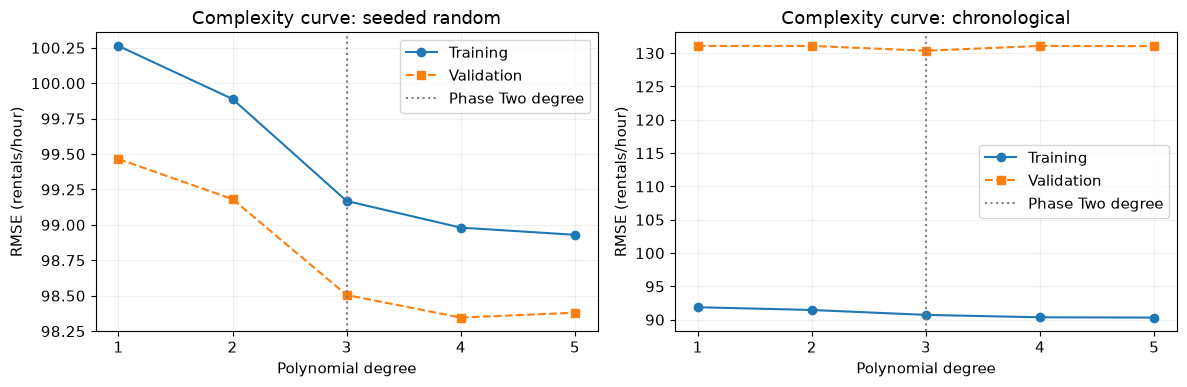

,split,degree,predictors,train_R2,train_RMSE,validation_R2,validation_RMSE,RMSE_gap,iterations,status,optimum_RMSE_gap
2,seeded random,3,59,0.70036,99.16864,0.70375,98.50538,-0.66326,20,converged,0.0
7,chronological,3,59,0.70296,90.72080,0.64089,130.36306,39.64226,5702,converged,0.0


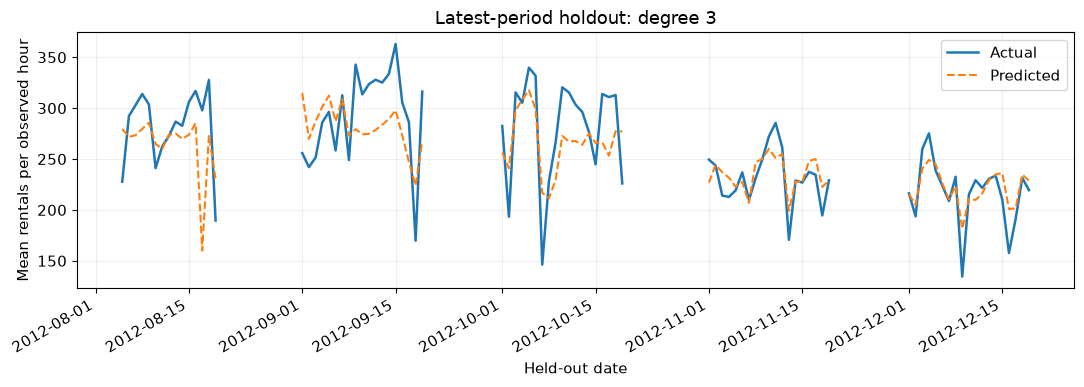

In [19]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,split in zip(axes,["seeded random","chronological"]):
    table=phase_three_results[phase_three_results.split==split]
    ax.plot(table.degree,table.train_RMSE,marker="o",label="Training")
    ax.plot(table.degree,table.validation_RMSE,marker="s",linestyle="--",label="Validation")
    ax.axvline(phase_three_anchor,color="gray",linestyle=":",label="Phase Two degree")
    ax.set(xlabel="Polynomial degree",ylabel="RMSE (rentals/hour)",title=f"Complexity curve: {split}",xticks=phase_three_degrees)
    ax.legend()
fig.tight_layout()
plt.show()

phase_three_anchor_comparison=phase_three_results[phase_three_results.degree==phase_three_anchor].copy()
display(phase_three_anchor_comparison.round(5))
chrono_anchor=phase_three_chronological[phase_three_anchor]
chrono_daily=pd.DataFrame({"date":pd.to_datetime(chrono_val.dteday).to_numpy(),"actual":chrono_y_val,
                           "predicted":chrono_anchor["validation_predictions"]}).groupby("date").mean()
# Preserve missing labeled dates as gaps, not interpolated observations.
chrono_daily=chrono_daily.reindex(pd.date_range(chrono_daily.index.min(),chrono_daily.index.max(),freq="D"))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(chrono_daily.index,chrono_daily.actual,label="Actual",linewidth=1.8)
ax.plot(chrono_daily.index,chrono_daily.predicted,label="Predicted",linestyle="--")
ax.set(xlabel="Held-out date",ylabel="Mean rentals per observed hour",title=f"Latest-period holdout: degree {phase_three_anchor}")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


### 4. Choose the next degree and explain the pattern
Choose the lowest seeded-validation RMSE, following the required tuning split. Report the chronological ranking too, even if it disagrees. Falling training error with rising validation error suggests overfitting. Similar errors alone do not prove that a model captures all useful patterns.

In [20]:
phase_three_target_degree=int(phase_three_random_table.sort_values(["validation_RMSE","degree"]).iloc[0].degree)
phase_three_chrono_table=phase_three_results[phase_three_results.split=="chronological"]
phase_three_chrono_best=int(phase_three_chrono_table.sort_values(["validation_RMSE","degree"]).iloc[0].degree)
phase_three_random_anchor=phase_three_random[phase_three_anchor]
phase_three_chrono_anchor=phase_three_chronological[phase_three_anchor]
phase_three_time_rmse_gap=phase_three_chrono_anchor["validation_metrics"]["RMSE"]-phase_three_random_anchor["validation_metrics"]["RMSE"]
phase_three_train_gain=phase_three_random_table.iloc[0].train_RMSE-phase_three_random_table.iloc[-1].train_RMSE
phase_three_val_gain=phase_three_random_table.iloc[0].validation_RMSE-phase_three_random_table.iloc[-1].validation_RMSE
print("Seeded-validation target degree:",phase_three_target_degree)
print("Chronological best degree on this one cutoff:",phase_three_chrono_best)
print("Degree-3 chronological minus random validation RMSE:",phase_three_time_rmse_gap)
print("Degree 1→5 training/validation RMSE reductions:",phase_three_train_gain,phase_three_val_gain)


Seeded-validation target degree: 4
Chronological best degree on this one cutoff: 3
Degree-3 chronological minus random validation RMSE: 31.85768101823686
Degree 1→5 training/validation RMSE reductions: 1.3331641445135602 1.0851901817083984


### Diagnosis and Phase Four plan
On the random split, degree 3 has training/validation RMSE about **99.17/98.51**. There is no large gap suggesting strong random-split overfitting. Degree 5 slightly worsens validation error after degree 4, despite lower training error: a small sign of extra variance.

Later-date performance is much weaker: degree-3 validation RMSE is **130.36**, with R² **0.6409**, versus **98.51/0.7038** randomly. Earlier/later target means also differ (**174.45/259.85**). This supports concern about future periods, not a claim that overfitting alone causes the gap.

Carry **degree 4** into Phase Four because it wins the required random validation comparison (**98.35 RMSE**). The chronological comparison prefers degree 3 (**130.36**, versus degree 4's **131.08**), so the choice is not universally best. Test weak and moderate penalties as well as near-zero penalties. Strong shrinkage may increase bias and is not guaranteed to fix changing demand.

In [21]:
phase_three_diagnosis = {
    "phase_two_fit_verdict": "reasonably fitted on the seeded split within the tested additive basis",
    "random_split_evidence": "small train/validation gap; mild degree-5 variance reversal; substantial residual error remains",
    "future_period_verdict": "temporal generalization weakness; random validation is optimistic for this later-period holdout",
    "causal_limit": "the chronological gap does not separate temporal distribution shift, approximation bias and estimator variance",
    "trusted_future_estimate": "chronological, with the limitation of one cutoff",
    "target_degree_reason": "degree 4 minimizes the required seeded-validation RMSE; degree 3 is better on the disclosed chronological check",
    "regularization_implication": "test zero/near-zero, weak and moderate L1/L2/Elastic Net penalties; do not assume strong shrinkage fixes temporal shift"
}
phase_three_target=phase_three_random[phase_three_target_degree]
phase_three_target_basis=phase_three_target["basis"]
phase_three_artifact={
    "phase":3,"seed":seed,"anchor_degree":phase_three_anchor,
    "phase_two_input_sha256":hashlib.sha256(phase_three_input_path.read_bytes()).hexdigest(),
    "source_sha256":phase_three_input["source_sha256"],
    "tested_degrees":phase_three_degrees,"target_degree":phase_three_target_degree,
    "expanded_features":phase_three_features,"basis":phase_three_input["basis"],
    "diagnosis":phase_three_diagnosis,
    "results":json.loads(phase_three_results.to_json(orient="records")),
    "train_record_ids":train_df.instant.tolist(),"validation_record_ids":val_df.instant.tolist(),
    "target_weight_names":phase_three_target_basis["names"],
    "target_weights":phase_three_target["run"]["weights"].tolist(),
    "target_preprocessing":{"base":phase_three_input["preprocessing"]["base"],
        "power_input":"Phase One standardized continuous columns",
        "new_term_names":phase_three_target_basis["term_names"],
        "new_term_means":phase_three_target_basis["term_means"].tolist(),
        "new_term_scales":phase_three_target_basis["term_scales"].tolist()},
    "target_metrics":{"training":phase_three_target["train_metrics"],"validation":phase_three_target["validation_metrics"]},
    "optimizer":{"function":"Phase One gradient_descent","rate_rule":"1 / largest training Hessian eigenvalue",
        "learning_rate":phase_three_target["run"]["learning_rate"],"iterations":phase_three_target["run"]["iterations"],
        "status":phase_three_target["run"]["status"],**phase_three_settings},
    "chronological":{"cutoff":phase_three_cutoff.isoformat(),"rule":"date at the 80-percent sorted-row boundary; complete dates held out",
        "train_record_ids":chrono_train.instant.tolist(),"validation_record_ids":chrono_val.instant.tolist(),
        "anchor_training_metrics":phase_three_chrono_anchor["train_metrics"],
        "anchor_validation_metrics":phase_three_chrono_anchor["validation_metrics"],
        "anchor_random_to_chronological_RMSE_increase":phase_three_time_rmse_gap,
        "best_tested_degree":phase_three_chrono_best,
        "training_target_mean":float(chrono_y_train.mean()),"validation_target_mean":float(chrono_y_val.mean()),
        "preprocessing":{"levels":chrono_levels,"feature_names":chrono_feature_names,
            "means":chrono_means.to_dict(),"scales":chrono_scales.to_dict(),"weather_mapping":{"4":3}},
        "anchor_weight_names":phase_three_chrono_anchor["basis"]["names"],
        "anchor_weights":phase_three_chrono_anchor["run"]["weights"].tolist(),
        "anchor_term_means":phase_three_chrono_anchor["basis"]["means"],
        "anchor_term_scales":phase_three_chrono_anchor["basis"]["scales"]},
    "requirements_checked":["Phase Two degree and feature choice consumed","complexity varied with training and held-out R2/RMSE",
        "one chronological split","random versus chronological estimates compared","future-data estimate justified",
        "evidence-based diagnosis and target degree for Phase Four","Expectation and Outcome present"]
}
phase_three_artifact_path=artifact_dir / "phase_three.json"
phase_three_artifact_path.write_text(json.dumps(phase_three_artifact,indent=2),encoding="utf-8")
print("Phase Four handoff:",phase_three_artifact_path.relative_to(PROJECT_DIR))
print("Diagnosis:",phase_three_diagnosis["phase_two_fit_verdict"])
print("Target degree:",phase_three_target_degree)


Phase Four handoff: artifacts\phase_three.json
Diagnosis: reasonably fitted on the seeded split within the tested additive basis
Target degree: 4


### Results summary
Print the selected degree, chronological cutoff and the measured gap. The diagnosis is saved with these results in `artifacts/phase_three.json`.

In [22]:
display(Markdown(
    f"The Phase Two anchor is **degree {phase_three_anchor}**. The seeded split's best tested complexity is "
    f"**degree {phase_three_target_degree}**, while the chronological split's best is **degree {phase_three_chrono_best}**. "
    f"For degree {phase_three_anchor}, random validation R²/RMSE are "
    f"**{phase_three_random_anchor['validation_metrics']['R2']:.4f} / {phase_three_random_anchor['validation_metrics']['RMSE']:.2f}**; "
    f"chronological validation R²/RMSE are **{phase_three_chrono_anchor['validation_metrics']['R2']:.4f} / "
    f"{phase_three_chrono_anchor['validation_metrics']['RMSE']:.2f}**. "
    f"The chronological RMSE difference is **{phase_three_time_rmse_gap:+.2f} rentals/hour**. "
    f"The single cutoff is **{phase_three_cutoff.date()}**, with **{len(chrono_train):,} earlier training** "
    f"and **{len(chrono_val):,} later validation** rows. "
    "All fitted transformations for that comparison use only earlier training observations."
))


The Phase Two anchor is **degree 3**. The seeded split's best tested complexity is **degree 4**, while the chronological split's best is **degree 3**. For degree 3, random validation R²/RMSE are **0.7038 / 98.51**; chronological validation R²/RMSE are **0.6409 / 130.36**. The chronological RMSE difference is **+31.86 rentals/hour**. The single cutoff is **2012-08-05**, with **8,703 earlier training** and **2,183 later validation** rows. All fitted transformations for that comparison use only earlier training observations.

### Outcome
Degree **4** has the lowest required random-validation RMSE (**98.35**), while the one later-date split prefers degree **3** (**130.36**). Degree 3's random-validation RMSE is **98.51**, so the time gap is much larger than the benefit of adding another power.

The degree-3 model is reasonably fitted within this tested additive family on random validation, but is less reliable for later periods. This changes our confidence in deployment. Carry degree 4 and this diagnosis into Phase Four; do not assume a penalty will fix changing demand.

## Phase Four: Lasso, Ridge and Elastic Net

**Goal:** Compare penalties and choose features for the classifier.

### Expectation

*Kept from the phase’s first run.*

Before running: Phase Three found only mild random-split complexity sensitivity but material temporal generalization weakness. Weak or moderate penalties may stabilize redundant degree-4 coefficients; strong shrinkage may increase bias. L1 and Elastic Net should remove some encoded terms, while L2 generally retains them. Regularization need not repair the temporal distribution difference. We will compare all three on the unchanged seeded validation rows, include the unpenalized baseline, and report evidence for every original input column.

### 1. Read Phase Three's diagnosis
Use its target degree **4**, the same split and the same 62 scaled predictors. Check the saved feature order and input hashes. Its mild random-split fitting problem is why we test small penalties as well as stronger ones. Do not penalize the intercept.

In [23]:
phase_four_input_path=artifact_dir / "phase_three.json"
phase_four_input=json.loads(phase_four_input_path.read_text(encoding="utf-8"))
assert phase_four_input["seed"]==seed
assert phase_four_input["train_record_ids"]==train_df.instant.tolist()
assert phase_four_input["validation_record_ids"]==val_df.instant.tolist()
assert phase_four_input["phase_two_input_sha256"]==hashlib.sha256(phase_three_input_path.read_bytes()).hexdigest()
for filename,digest in phase_four_input["source_sha256"].items():
    assert hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest()==digest
phase_four_degree=phase_four_input["target_degree"]
phase_four_basis=polynomial_design(phase_four_degree)
assert phase_four_basis["names"]==phase_four_input["target_weight_names"]
phase_four_names=phase_four_basis["names"][1:]
phase_four_X=phase_four_basis["train"][:,1:]
phase_four_V=phase_four_basis["validation"][:,1:]
phase_four_initial=np.asarray(phase_four_input["target_weights"])[1:]
print("Consumed degree:",phase_four_degree)
display(Markdown(str(phase_four_input["diagnosis"])))


Consumed degree: 4


{'phase_two_fit_verdict': 'reasonably fitted on the seeded split within the tested additive basis', 'random_split_evidence': 'small train/validation gap; mild degree-5 variance reversal; substantial residual error remains', 'future_period_verdict': 'temporal generalization weakness; random validation is optimistic for this later-period holdout', 'causal_limit': 'the chronological gap does not separate temporal distribution shift, approximation bias and estimator variance', 'trusted_future_estimate': 'chronological, with the limitation of one cutoff', 'target_degree_reason': 'degree 4 minimizes the required seeded-validation RMSE; degree 3 is better on the disclosed chronological check', 'regularization_implication': 'test zero/near-zero, weak and moderate L1/L2/Elastic Net penalties; do not assume strong shrinkage fixes temporal shift'}

### 2. Implement three penalties with one solver
Minimize:

$$\frac{1}{2m}\|y-b-Xw\|^2+\lambda\left[\frac{1-\rho}{2}\|w\|^2+\rho\|w\|_1\right].$$

- **Ridge/L2:** `rho=0`; shrinks weights, usually without making them zero.
- **Lasso/L1:** `rho=1`; can make weights exactly zero.
- **Elastic Net:** mixes both effects.

Our accelerated proximal-gradient solver takes a gradient step for the smooth part, then applies soft thresholding for L1. Soft thresholding moves small coefficients exactly to zero. Center training inputs/targets and calculate the unpenalized intercept afterward.

The KKT check measures whether the penalized solution satisfies its optimality conditions, including zero coefficients. Require residual below `1e-7*(1+max(abs(b)))`, with a 100,000-step limit. A separate closed-form Ridge check verifies the result; it does not supply the fitted weights.

In [24]:
def fit_regularized(X,y,lam,rho,initial=None,max_iter=100000,tol=1e-7):
    if lam<0 or not 0<=rho<=1:
        raise ValueError("Invalid regularization parameters")
    means=X.mean(axis=0); yc=y-y.mean(); A=X-means
    G=A.T@A/len(y); b=A.T@yc/len(y)
    l1,l2=lam*rho,lam*(1-rho)
    H=G+l2*np.eye(X.shape[1])
    step=1/float(np.linalg.eigvalsh(H).max())
    w=np.zeros(X.shape[1]) if initial is None else np.array(initial,dtype=float,copy=True)
    z=w.copy(); momentum=1.; threshold=tol*(1+np.abs(b).max())
    history=[]; status="max_iter"
    for iteration in range(1,max_iter+1):
        raw=z-step*(H@z-b)
        new=np.sign(raw)*np.maximum(np.abs(raw)-step*l1,0)
        grad=H@new-b
        active=new!=0
        residual=np.where(active,grad+l1*np.sign(new),np.sign(grad)*np.maximum(np.abs(grad)-l1,0))
        kkt=float(np.abs(residual).max())
        if iteration==1 or iteration%100==0 or kkt<=threshold:
            objective=float(0.5*np.mean((yc-A@new)**2)+0.5*l2*(new@new)+l1*np.abs(new).sum())
            history.append({"iteration":iteration,"objective":objective,"kkt":kkt})
        if kkt<=threshold:
            w=new; status="converged"; break
        next_momentum=(1+np.sqrt(1+4*momentum**2))/2
        restart = (z-new)@(new-w)>0
        z=new+(momentum-1)/next_momentum*(new-w)
        # Restart acceleration when the extrapolated step points uphill.
        if restart:
            z=new.copy(); next_momentum=1.
        w=new; momentum=next_momentum
    intercept=float(y.mean()-means@w)
    assert status=="converged",f"Regularized fit did not converge: lambda={lam}, rho={rho}, residual={kkt}"
    return {"weights":w,"intercept":intercept,"lambda":float(lam),"l1_ratio":float(rho),
            "iterations":iteration,"kkt":kkt,"kkt_tolerance":float(threshold),"status":status,"history":history}

def regularized_predict(model,X):
    return model["intercept"]+X@model["weights"]

phase_four_ridge_check=fit_regularized(phase_four_X,y_train,0.1,0,phase_four_initial)
check_A=phase_four_X-phase_four_X.mean(axis=0)
check_solution=np.linalg.solve(check_A.T@check_A/len(y_train)+0.1*np.eye(check_A.shape[1]),check_A.T@(y_train-y_train.mean())/len(y_train))
assert np.max(np.abs(phase_four_X@phase_four_ridge_check["weights"]-phase_four_X@check_solution))<0.01
print("Independent Ridge optimum check passed.")


Independent Ridge optimum check passed.


### 3. Compare the three methods fairly
Test lambda `0.0001, 0.001, 0.01, 0.1, 1, 10, 100`. For Elastic Net also test mixing ratios `0.2, 0.5, 0.8`. That makes **35 candidates**. All use the same rows, scaling, starting weights and stopping check.

Select the lowest validation RMSE for each method and compare with the unpenalized degree-4 result. Report R²/RMSE and nonzero counts. For the Elastic Net plot, each lambda uses its best mixing ratio at that lambda.

,method,lambda,l1_ratio,train_R2,train_RMSE,validation_R2,validation_RMSE,nonzero,iterations,kkt
28,Elastic Net,0.0001,0.8,0.701492,98.980768,0.704709,98.345890,62,1446,0.000007
9,Lasso,0.0100,1.0,0.701491,98.980978,0.704721,98.343834,57,693,0.000007
0,Ridge,0.0001,0.0,0.701492,98.980790,0.704707,98.346272,62,119,0.000007


Unpenalized degree-4 validation: {'R2': 0.7047096277491695, 'RMSE': 98.34580344724712}
Best regularized method: Lasso {'R2': 0.7047214520446952, 'RMSE': 98.34383439983758}
Lasso retained: 57 / 62
Elastic Net retained: 62 / 62


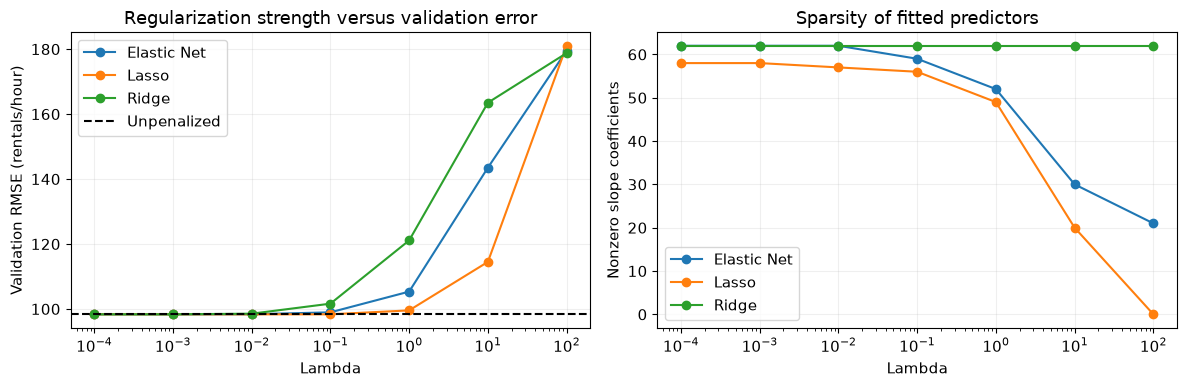

In [25]:
phase_four_lambdas=[0.0001,0.001,0.01,0.1,1.,10.,100.]
phase_four_ratios={"Ridge":[0.],"Lasso":[1.],"Elastic Net":[0.2,0.5,0.8]}
phase_four_models=[]; phase_four_rows=[]
for method,ratios in phase_four_ratios.items():
    for rho in ratios:
        for lam in phase_four_lambdas:
            fit=fit_regularized(phase_four_X,y_train,lam,rho,phase_four_initial)
            ts=regression_metrics(y_train,regularized_predict(fit,phase_four_X))
            vs=regression_metrics(y_val,regularized_predict(fit,phase_four_V))
            phase_four_models.append(fit)
            phase_four_rows.append({"method":method,"lambda":lam,"l1_ratio":rho,
                "train_R2":ts["R2"],"train_RMSE":ts["RMSE"],"validation_R2":vs["R2"],"validation_RMSE":vs["RMSE"],
                "nonzero":int(np.count_nonzero(fit["weights"])),"iterations":fit["iterations"],"kkt":fit["kkt"]})
phase_four_search=pd.DataFrame(phase_four_rows)
phase_four_winner_indices={method:int(group.sort_values(["validation_RMSE","lambda"]).index[0]) for method,group in phase_four_search.groupby("method")}
phase_four_winners=phase_four_search.loc[list(phase_four_winner_indices.values())].copy()
display(phase_four_winners.round(6))
phase_four_best_index=int(phase_four_winners.sort_values("validation_RMSE").index[0])
phase_four_best=phase_four_models[phase_four_best_index]
phase_four_best_method=str(phase_four_search.loc[phase_four_best_index,"method"])
phase_four_best_metrics=regression_metrics(y_val,regularized_predict(phase_four_best,phase_four_V))
phase_four_baseline=phase_four_input["target_metrics"]["validation"]
print("Unpenalized degree-4 validation:",phase_four_baseline)
print("Best regularized method:",phase_four_best_method,phase_four_best_metrics)

phase_four_lasso=phase_four_models[phase_four_winner_indices["Lasso"]]
phase_four_elastic=phase_four_models[phase_four_winner_indices["Elastic Net"]]
phase_four_lasso_features=[f for f,w in zip(phase_four_names,phase_four_lasso["weights"]) if w!=0]
phase_four_elastic_features=[f for f,w in zip(phase_four_names,phase_four_elastic["weights"]) if w!=0]
print("Lasso retained:",len(phase_four_lasso_features),"/",len(phase_four_names))
print("Elastic Net retained:",len(phase_four_elastic_features),"/",len(phase_four_names))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for method,group in phase_four_search.groupby("method"):
    curve=group.sort_values("validation_RMSE").groupby("lambda").first().sort_index()
    axes[0].plot(curve.index,curve.validation_RMSE,marker="o",label=method)
    axes[1].plot(curve.index,curve.nonzero,marker="o",label=method)
axes[0].axhline(phase_four_baseline["RMSE"],color="black",linestyle="--",label="Unpenalized")
axes[0].set(xlabel="Lambda",ylabel="Validation RMSE (rentals/hour)",title="Regularization strength versus validation error")
axes[1].set(xlabel="Lambda",ylabel="Nonzero slope coefficients",title="Sparsity of fitted predictors")
for ax in axes:
    ax.set_xscale("log"); ax.legend()
fig.tight_layout(); plt.show()


### 4. Test each original input column
Group derived terms by their original source. Remove one group, refit at the winning method's fixed settings, and measure the validation RMSE change. This is an ablation test: it asks what happens without that group while the other inputs remain.

We chose a practical rule before this comparison: a removal cost above **0.1 rentals/hour** means useful. Otherwise, call it redundant only if the other features reconstruct it with validation R² at least **0.90**; call it uninformative in this model otherwise. These are chosen sensitivity limits, not significance tests. Show exact numbers so borderline labels remain clear.

`instant` was excluded earlier, so test adding it instead. `dteday` here means the extra day-of-month term; year/month remain separately available. `cnt` is target-only. These tests use no hidden-test targets and do not prove causality.

In [26]:
phase_four_groups={
    "yr":["yr"],"holiday":["holiday"],"workingday":["workingday"],
    "temp":[f for f in phase_four_names if f=="temp" or f.startswith("temp^")],
    "atemp":["atemp"],"hum":[f for f in phase_four_names if f=="hum" or f.startswith("hum^")],
    "windspeed":[f for f in phase_four_names if f=="windspeed" or f.startswith("windspeed^")],
    "dteday":["day_of_month"]}
for original in ["hr","season","weathersit","weekday","mnth"]:
    phase_four_groups[original]=[f for f in phase_four_names if f.startswith(original+"_")]

def reconstruction_r2(train_other,val_other,train_group,val_group):
    A=np.column_stack([np.ones(len(train_other)),train_other])
    B=np.column_stack([np.ones(len(val_other)),val_other])
    coefficients=np.linalg.lstsq(A,train_group,rcond=None)[0]
    denominator=float(((val_group-val_group.mean(axis=0))**2).sum())
    return float(1-((val_group-B@coefficients)**2).sum()/denominator) if denominator else 0.

phase_four_verdict_rows=[]
for original in [c for c in train_all if c not in ["instant","cnt"]]:
    indices=[phase_four_names.index(f) for f in phase_four_groups[original]]
    keep=[i for i in range(len(phase_four_names)) if i not in indices]
    ablated=fit_regularized(phase_four_X[:,keep],y_train,phase_four_best["lambda"],phase_four_best["l1_ratio"],phase_four_best["weights"][keep])
    ablated_score=regression_metrics(y_val,regularized_predict(ablated,phase_four_V[:,keep]))
    delta=ablated_score["RMSE"]-phase_four_best_metrics["RMSE"]
    reconstruction=reconstruction_r2(phase_four_X[:,keep],phase_four_V[:,keep],phase_four_X[:,indices],phase_four_V[:,indices])
    verdict="useful" if delta>0.1 else ("redundant" if reconstruction>=0.9 else "uninformative")
    phase_four_verdict_rows.append({"column":original,"verdict":verdict,"derived_terms":len(indices),
        "refit_validation_RMSE":ablated_score["RMSE"],"removal_RMSE_increase":delta,"reconstruction_R2":reconstruction,
        "lasso_nonzero":sum(phase_four_lasso["weights"][i]!=0 for i in indices),
        "elastic_nonzero":sum(phase_four_elastic["weights"][i]!=0 for i in indices)})
instant_mean=float(train_df.instant.mean()); instant_scale=float(train_df.instant.std(ddof=0))
instant_train=((train_df.instant.to_numpy()-instant_mean)/instant_scale)[:,None]
instant_val=((val_df.instant.to_numpy()-instant_mean)/instant_scale)[:,None]
instant_augmented=fit_regularized(np.column_stack([phase_four_X,instant_train]),y_train,phase_four_best["lambda"],phase_four_best["l1_ratio"],np.r_[phase_four_best["weights"],0.])
instant_score=regression_metrics(y_val,regularized_predict(instant_augmented,np.column_stack([phase_four_V,instant_val])))
instant_gain=phase_four_best_metrics["RMSE"]-instant_score["RMSE"]
instant_reconstruction=reconstruction_r2(phase_four_X,phase_four_V,instant_train,instant_val)
phase_four_verdict_rows.append({"column":"instant","verdict":"useful" if instant_gain>0.1 else ("redundant" if instant_reconstruction>=0.9 else "uninformative"),
    "derived_terms":0,"refit_validation_RMSE":instant_score["RMSE"],"removal_RMSE_increase":instant_gain,
    "reconstruction_R2":instant_reconstruction,"lasso_nonzero":0,"elastic_nonzero":0})
phase_four_verdicts=pd.DataFrame(phase_four_verdict_rows).set_index("column").loc[[c for c in train_all if c!="cnt"]].reset_index()
assert set(phase_four_verdicts.column)==set(train_all.columns)-{"cnt"}
display(phase_four_verdicts.round(5))
print("instant row is an add-feature diagnostic: positive delta means adding the index improved RMSE; it is not part of the inherited basis.")
print("cnt: target only; excluded from all predictors.")


,column,verdict,derived_terms,refit_validation_RMSE,removal_RMSE_increase,reconstruction_R2,lasso_nonzero,elastic_nonzero
0,instant,redundant,0,98.33472,0.00912,0.99999,0,0
1,dteday,uninformative,1,98.43302,0.08919,0.02710,1,1
2,season,redundant,3,98.34204,-0.00179,1.00000,3,3
3,yr,useful,1,107.78160,9.43777,0.04640,1,1
4,mnth,useful,11,99.54268,1.19885,0.35750,8,11
5,hr,useful,23,144.06879,45.72496,0.01519,23,23
6,holiday,redundant,1,98.33862,-0.00521,1.00000,1,1
7,weekday,useful,6,98.46068,0.11684,0.14247,5,6
8,workingday,redundant,1,98.34240,-0.00143,1.00000,1,1
9,weathersit,useful,2,99.52200,1.17817,0.15457,2,2


instant row is an add-feature diagnostic: positive delta means adding the index improved RMSE; it is not part of the inherited basis.
cnt: target only; excluded from all predictors.


### 5. Save the selected features for Phase Five
Save all three winning settings and their weights. For the classifier, use the exact nonzero subset from the selected **Lasso**, without the intercept. Save Elastic Net's subset too.

A group-removal test and a nonzero coefficient answer different questions. Correlated groups can replace one another after refitting, so we do not silently delete every group called redundant. Phase Five receives Lasso's exact 57-term mask in `artifacts/phase_four.json`.

In [27]:
phase_four_winning_models={}
for method,index in phase_four_winner_indices.items():
    fit=phase_four_models[index]
    phase_four_winning_models[method]={"lambda":fit["lambda"],"l1_ratio":fit["l1_ratio"],
        "intercept":fit["intercept"],"weights":fit["weights"].tolist(),
        "iterations":fit["iterations"],"kkt":fit["kkt"],"kkt_tolerance":fit["kkt_tolerance"],
        "metrics":phase_four_search.loc[index].to_dict()}
phase_four_artifact={"phase":4,"seed":seed,"degree":phase_four_degree,
    "phase_three_input_sha256":hashlib.sha256(phase_four_input_path.read_bytes()).hexdigest(),
    "phase_three_diagnosis":phase_four_input["diagnosis"],"source_sha256":phase_four_input["source_sha256"],
    "objective":"half_mse + lambda*((1-rho)/2*L2_squared + rho*L1); intercept unpenalized",
    "feature_names":phase_four_names,"preprocessing":phase_four_input["target_preprocessing"],
    "train_record_ids":train_df.instant.tolist(),"validation_record_ids":val_df.instant.tolist(),
    "winning_models":phase_four_winning_models,"search_results":json.loads(phase_four_search.to_json(orient="records")),
    "best_regularized_method":phase_four_best_method,
    "regression_recommendation":phase_four_best_method if phase_four_best_metrics["RMSE"]<phase_four_baseline["RMSE"] else "unpenalized Phase Three",
    "classifier_selection_method":"Lasso","selected_features":phase_four_lasso_features,
    "selected_indices":[phase_four_names.index(f) for f in phase_four_lasso_features],
    "elastic_net_selected_features":phase_four_elastic_features,
    "original_column_verdicts":json.loads(phase_four_verdicts.to_json(orient="records")),
    "verdict_policy":{"practical_RMSE_threshold":0.1,"reconstruction_R2_threshold":0.9,"conditional_on":"fixed winning hyperparameters and degree-4 basis"},
    "instant_diagnostic":{"added_feature_validation":instant_score,"validation_RMSE_gain":instant_gain,"included_in_pipeline":False},
    "target_role":{"cnt":"target, never a predictor"}}
phase_four_artifact_path=artifact_dir / "phase_four.json"
phase_four_artifact_path.write_text(json.dumps(phase_four_artifact,indent=2),encoding="utf-8")
print("Phase Five handoff:",phase_four_artifact_path.relative_to(PROJECT_DIR))


Phase Five handoff: artifacts\phase_four.json


### What the comparison shows
Lasso at lambda **0.01** is best: validation RMSE **98.34383**, compared with **98.34580** unpenalized. The difference is only **0.00197** rentals/hour, so the accuracy gain is negligible. Its main benefit is keeping **57 of 62** terms. Ridge and Elastic Net prefer the weakest tested penalties.

Hour and year are strong contributors. Season and some working-day/calendar inputs overlap with other columns. Day-of-month's removal cost is **0.0892**, just below our 0.1 sensitivity limit; this does not mean all date information is useless. Strong penalties hurt, and none of this shows that the time gap is fixed.

### Results summary
Print the winning settings, scores and retained feature counts. All numbers come from the same required validation rows.

In [28]:
phase_four_gain=phase_four_baseline["RMSE"]-phase_four_best_metrics["RMSE"]
display(Markdown(
    f"Compared **Lasso, Ridge and Elastic Net** on the same degree-{phase_four_degree} basis. "
    f"Best regularized method: **{phase_four_best_method}**, lambda **{phase_four_best['lambda']:g}**, "
    f"rho **{phase_four_best['l1_ratio']:g}**. Validation R² **{phase_four_best_metrics['R2']:.4f}**, "
    f"RMSE **{phase_four_best_metrics['RMSE']:.4f} rentals/hour**; reduction versus unpenalized degree 4: "
    f"**{phase_four_gain:.4f}** (negative means worse). Lasso retains **{len(phase_four_lasso_features)} / "
    f"{len(phase_four_names)}** terms; Elastic Net retains **{len(phase_four_elastic_features)}**. "
    "Every original input has a numeric ablation/addition verdict, and `cnt` is explicitly target-only. "
    "The exact Lasso subset, all three winning settings and the Phase Three diagnosis are saved for Phase Five. "
    "Small validation differences and correlated feature substitutions should not be interpreted as universal feature rankings."
))


Compared **Lasso, Ridge and Elastic Net** on the same degree-4 basis. Best regularized method: **Lasso**, lambda **0.01**, rho **1**. Validation R² **0.7047**, RMSE **98.3438 rentals/hour**; reduction versus unpenalized degree 4: **0.0020** (negative means worse). Lasso retains **57 / 62** terms; Elastic Net retains **62**. Every original input has a numeric ablation/addition verdict, and `cnt` is explicitly target-only. The exact Lasso subset, all three winning settings and the Phase Three diagnosis are saved for Phase Five. Small validation differences and correlated feature substitutions should not be interpreted as universal feature rankings.

### Outcome
All three methods were compared. Selected lambda: **Lasso 0.01**, **Ridge 0.0001**, **Elastic Net 0.0001 with ratio 0.8**. Lasso's validation RMSE is **98.34383**, barely better than the unpenalized **98.34580**.

The important change is a smaller feature set: **57 of 62** terms remain. It was useful to find that stronger shrinkage hurt rather than helped. Every original input has numeric evidence for its verdict; the exact Lasso mask goes to Phase Five.

## Phase Five: logistic regression and final submission

**Goal:** Predict relative high demand and produce the final submission files.

### Expectation

*Kept from the phase’s first run.*

Before running: a global rental cutoff would mostly distinguish peak hours from quiet nights. Define unusually high demand relative to the training 75th percentile for the same hour and working-day status instead. This should make positives approximately one quarter of comparable training hours, although validation prevalence may differ. The classifier will use only Phase Four's Lasso survivors. Calendar and weather may predict elevated demand, but residual variation and the temporal weakness seen in Phase Three may limit discrimination. Accuracy alone may look good for a majority-negative model, so report F1 and ROC-AUC as required, plus precision and recall.

### 1. Use only Phase Four's selected features
Read its artifact and check the feature order, split IDs and hashes. Select exactly the **57 Lasso survivors** from the degree-4 matrix, plus an intercept. No removed feature is added back.

In [29]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve)
phase_five_input_path=artifact_dir / "phase_four.json"
phase_five_input=json.loads(phase_five_input_path.read_text(encoding="utf-8"))
assert phase_five_input["seed"]==seed
assert phase_five_input["train_record_ids"]==train_df.instant.tolist()
assert phase_five_input["validation_record_ids"]==val_df.instant.tolist()
assert phase_five_input["phase_three_input_sha256"]==hashlib.sha256(phase_four_input_path.read_bytes()).hexdigest()
for filename,digest in phase_five_input["source_sha256"].items():
    assert hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest()==digest
phase_five_names=phase_five_input["selected_features"]
phase_five_indices=phase_five_input["selected_indices"]
assert phase_five_names==[phase_five_input["feature_names"][i] for i in phase_five_indices]
assert all(phase_five_input["winning_models"]["Lasso"]["weights"][i]!=0 for i in phase_five_indices)
assert phase_four_names==phase_five_input["feature_names"]
classification_X=np.column_stack([np.ones(len(y_train)),phase_four_X[:,phase_five_indices]])
classification_V=np.column_stack([np.ones(len(y_val)),phase_four_V[:,phase_five_indices]])
print("Classifier inputs:",len(phase_five_names),"selected terms plus intercept")


Classifier inputs: 57 selected terms plus intercept


### 2. Define a fairer high-demand label
Call an hour high demand when `cnt` is above the **training 75th percentile for the same hour and working-day status**. This means unusually busy compared with similar hours, not an absolute station-capacity limit. A global count cutoff would mostly separate busy daytime hours from quiet nights.

Choose the 75th percentile before fitting; do not search quantiles. Groups need at least 30 training rows so a small group does not set its own unstable cutoff. Otherwise fall back to the training hour cutoff, then the training global cutoff. These are practical choices, not guarantees.

Use strict `>` for integer ties. Apply those training cutoffs to validation counts to obtain evaluation labels; do not calculate validation quantiles. The plot compares the two label definitions.

,partition,rows,high_demand,positive_rate
0,training,8708,2145,0.246325
1,validation,2178,557,0.255739


,hour,workingday,training_rows,cutoff,source
0,0,0,112,121.25,group
1,0,1,247,47.00,group
2,1,0,109,93.00,group
3,1,1,261,21.00,group
4,2,0,119,69.50,group
5,2,1,250,11.00,group
6,3,0,118,32.00,group
7,3,1,232,6.25,group


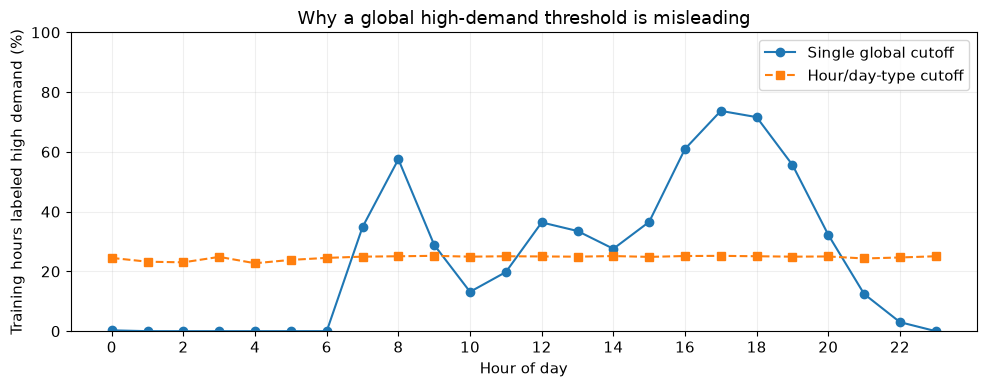

In [30]:
phase_five_quantile=0.75
phase_five_min_group=30
phase_five_global_cutoff=float(train_df.cnt.quantile(phase_five_quantile))
phase_five_hour_cutoffs={int(h):float(s.quantile(phase_five_quantile)) for h,s in train_df.groupby("hr").cnt}
phase_five_group_cutoffs={}
phase_five_group_rows=[]
for (hour,working),frame in train_df.groupby(["hr","workingday"]):
    cutoff=float(frame.cnt.quantile(phase_five_quantile)) if len(frame)>=phase_five_min_group else phase_five_hour_cutoffs[int(hour)]
    phase_five_group_cutoffs[(int(hour),int(working))]=cutoff
    phase_five_group_rows.append({"hour":int(hour),"workingday":int(working),"training_rows":len(frame),"cutoff":cutoff,
                                  "source":"group" if len(frame)>=phase_five_min_group else "hour fallback"})

def contextual_thresholds(frame):
    return np.array([phase_five_group_cutoffs.get((int(h),int(w)),phase_five_hour_cutoffs.get(int(h),phase_five_global_cutoff))
                     for h,w in zip(frame.hr,frame.workingday)])

classification_y=(y_train>contextual_thresholds(train_df)).astype(int)
classification_y_val=(y_val>contextual_thresholds(val_df)).astype(int)
assert set(np.unique(classification_y))=={0,1} and set(np.unique(classification_y_val))=={0,1}
display(pd.DataFrame({"partition":["training","validation"],"rows":[len(y_train),len(y_val)],
    "high_demand":[int(classification_y.sum()),int(classification_y_val.sum())],
    "positive_rate":[classification_y.mean(),classification_y_val.mean()]}))
display(pd.DataFrame(phase_five_group_rows).head(8))
label_profiles=train_df.assign(global_label=(y_train>phase_five_global_cutoff).astype(int),contextual_label=classification_y).groupby("hr")[["global_label","contextual_label"]].mean()
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(label_profiles.index,100*label_profiles.global_label,marker="o",label="Single global cutoff")
ax.plot(label_profiles.index,100*label_profiles.contextual_label,marker="s",linestyle="--",label="Hour/day-type cutoff")
ax.set(xlabel="Hour of day",ylabel="Training hours labeled high demand (%)",title="Why a global high-demand threshold is misleading",xticks=range(0,24,2),ylim=(0,100))
ax.legend(); fig.tight_layout(); plt.show()


### 3. Train logistic regression
The classifier estimates $P(\text{high demand})=\operatorname{sigmoid}(X\beta)$. Minimize mean binary cross-entropy, optionally with L2 shrinkage on the slopes. The intercept is not penalized.

Use a stable sigmoid and `logaddexp` so large numbers do not overflow. Start slopes at zero and the intercept at training log-odds. Rental-count weights have different units, so they are not suitable starting classifier weights; the required input here is the selected feature subset.

Our damped Newton solver uses the gradient and Hessian to choose an update. Backtracking shortens a step until loss decreases. A linear solve finds the update direction; it is not a library classifier fit. Check the gradient by finite differences and stop below `1e-7`, with a 100-step limit.

Test L2 lambda `0, 0.0001, 0.001, 0.01, 0.1`. Choose by validation ROC-AUC; exact ties favor the smaller penalty. Do not change the 57 inputs during this search.

In [31]:
def stable_sigmoid(z):
    e=np.exp(-np.abs(z))
    return np.where(z>=0,1/(1+e),e/(1+e))

def logistic_objective(A,y,beta,lam):
    logits=A@beta
    return float(np.mean(np.logaddexp(0,logits)-y*logits)+0.5*lam*(beta[1:]@beta[1:]))

def train_logistic(A,y,lam=0.,tol=1e-7,max_iter=100):
    beta=np.zeros(A.shape[1]); prevalence=float(y.mean())
    beta[0]=np.log(prevalence/(1-prevalence))
    penalty=np.r_[0.,np.ones(A.shape[1]-1)]
    history=[logistic_objective(A,y,beta,lam)]
    for iteration in range(max_iter+1):
        probability=stable_sigmoid(A@beta)
        gradient=A.T@(probability-y)/len(y)+lam*penalty*beta
        gradient_max=float(np.abs(gradient).max())
        if gradient_max<tol: break
        if iteration==max_iter: raise RuntimeError("Logistic optimizer failed to converge")
        variance=probability*(1-probability)
        H=A.T@(A*variance[:,None])/len(y)+lam*np.diag(penalty)
        direction=np.linalg.lstsq(H,gradient,rcond=1e-12)[0]
        step=1.
        for backtrack in range(50):
            candidate=beta-step*direction
            loss=logistic_objective(A,y,candidate,lam)
            if loss<=history[-1]-1e-4*step*float(gradient@direction): break
            step*=0.5
        else: raise RuntimeError("Logistic line search failed")
        beta=candidate; history.append(loss)
    assert np.all(np.diff(history)<=1e-10)
    return {"weights":beta,"lambda":float(lam),"iterations":iteration,"gradient_max":gradient_max,"history":history}

check_A=classification_X[:80]; check_y=classification_y[:80]
check_beta=np.linspace(-0.1,0.1,check_A.shape[1]); check_lambda=0.01
check_gradient=check_A.T@(stable_sigmoid(check_A@check_beta)-check_y)/len(check_y)+check_lambda*np.r_[0.,check_beta[1:]]
check_numeric=np.zeros_like(check_beta)
for j in range(len(check_beta)):
    perturb=np.zeros_like(check_beta); perturb[j]=1e-5
    check_numeric[j]=(logistic_objective(check_A,check_y,check_beta+perturb,check_lambda)-logistic_objective(check_A,check_y,check_beta-perturb,check_lambda))/(2e-5)
assert np.allclose(check_gradient,check_numeric,atol=1e-7,rtol=1e-5)
phase_five_models=[]; phase_five_rows=[]
for lam in [0.,0.0001,0.001,0.01,0.1]:
    model=train_logistic(classification_X,classification_y,lam)
    train_probability=stable_sigmoid(classification_X@model["weights"])
    val_probability=stable_sigmoid(classification_V@model["weights"])
    phase_five_models.append(model)
    phase_five_rows.append({"lambda":lam,"iterations":model["iterations"],"gradient_max":model["gradient_max"],
        "training_ROC_AUC":roc_auc_score(classification_y,train_probability),"validation_ROC_AUC":roc_auc_score(classification_y_val,val_probability),
        "validation_F1_at_0.5":f1_score(classification_y_val,val_probability>=0.5,zero_division=0)})
phase_five_search=pd.DataFrame(phase_five_rows)
display(phase_five_search.round(6))
phase_five_index=int(phase_five_search.sort_values(["validation_ROC_AUC","lambda"],ascending=[False,True]).index[0])
phase_five_model=phase_five_models[phase_five_index]
phase_five_train_probability=stable_sigmoid(classification_X@phase_five_model["weights"])
phase_five_val_probability=stable_sigmoid(classification_V@phase_five_model["weights"])


,lambda,iterations,gradient_max,training_ROC_AUC,validation_ROC_AUC,validation_F1_at_0.5
0,0.0000,7,0.0,0.911772,0.915988,0.753098
1,0.0001,7,0.0,0.911700,0.915841,0.752381
2,0.0010,7,0.0,0.911158,0.915261,0.750476
3,0.0100,6,0.0,0.908251,0.913153,0.736232
4,0.1000,5,0.0,0.899630,0.906415,0.602992


### 4. Choose the alert threshold and report scores
The count cutoffs define the labels. A separate probability threshold decides when the model raises an alert.

Show threshold **0.5** and search **0.05–0.95** in 0.01 steps for the highest validation F1. Ties favor recall, then a threshold closer to 0.5. F1 balances missed high-demand hours and false alerts; this is not a cost-optimal staffing rule.

Report accuracy, F1 and ROC-AUC as required, plus precision and recall. Compare with always predicting the training-majority class. Accuracy alone can hide failure to detect the smaller class. ROC-AUC measures ranking, so it does not change when only the alert threshold changes.

These are tuned validation scores: we used validation repeatedly to select settings. They are not independent future-period results.

,model,accuracy,precision,recall,F1,ROC_AUC,average_precision
0,Training-majority baseline,0.74426,0.00000,0.00000,0.00000,0.50000,0.25574
1,Logistic threshold 0.5,0.88108,0.80285,0.70916,0.75310,0.91599,0.79030
2,Logistic selected threshold 0.44,0.87879,0.77079,0.74865,0.75956,0.91599,0.79030


Training metrics at selected threshold: {'accuracy': 0.8640330730362885, 'precision': 0.7173224785165083, 'recall': 0.7393939393939394, 'F1': 0.7281910009182736, 'ROC_AUC': 0.9117723253941447, 'average_precision': 0.7668326369621752}


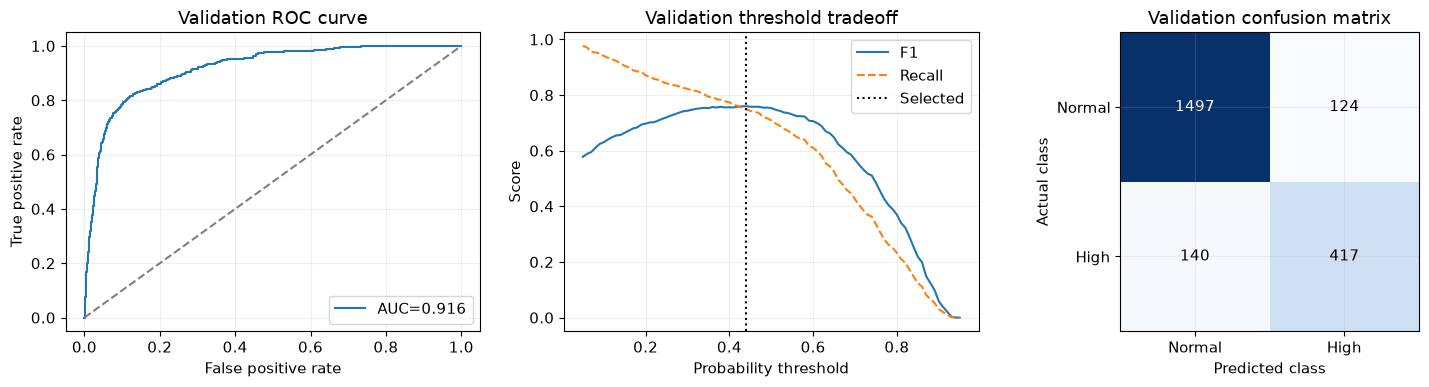

In [32]:
def classification_metrics(y,probability,threshold):
    prediction=(probability>=threshold).astype(int)
    return {"accuracy":float(accuracy_score(y,prediction)),"precision":float(precision_score(y,prediction,zero_division=0)),
        "recall":float(recall_score(y,prediction,zero_division=0)),"F1":float(f1_score(y,prediction,zero_division=0)),
        "ROC_AUC":float(roc_auc_score(y,probability)),"average_precision":float(average_precision_score(y,probability))}

phase_five_threshold_rows=[]
for threshold in np.linspace(0.05,0.95,91):
    phase_five_threshold_rows.append({"threshold":float(threshold),"distance_from_half":abs(float(threshold)-0.5),
        **classification_metrics(classification_y_val,phase_five_val_probability,threshold)})
phase_five_threshold_search=pd.DataFrame(phase_five_threshold_rows)
phase_five_threshold=float(phase_five_threshold_search.sort_values(["F1","recall","distance_from_half"],ascending=[False,False,True]).iloc[0].threshold)
phase_five_metrics=classification_metrics(classification_y_val,phase_five_val_probability,phase_five_threshold)
phase_five_default_metrics=classification_metrics(classification_y_val,phase_five_val_probability,0.5)
phase_five_training_metrics=classification_metrics(classification_y,phase_five_train_probability,phase_five_threshold)
majority_probability=np.full(len(classification_y_val),float(classification_y.mean()))
phase_five_baseline=classification_metrics(classification_y_val,majority_probability,0.5)
display(pd.DataFrame([{"model":"Training-majority baseline",**phase_five_baseline},
    {"model":"Logistic threshold 0.5",**phase_five_default_metrics},
    {"model":f"Logistic selected threshold {phase_five_threshold:.2f}",**phase_five_metrics}]).round(5))
print("Training metrics at selected threshold:",phase_five_training_metrics)
phase_five_confusion=confusion_matrix(classification_y_val,phase_five_val_probability>=phase_five_threshold,labels=[0,1])
fig,axes=plt.subplots(1,3,figsize=(15,4))
false_positive,true_positive,_=roc_curve(classification_y_val,phase_five_val_probability)
axes[0].plot(false_positive,true_positive,label=f"AUC={phase_five_metrics['ROC_AUC']:.3f}")
axes[0].plot([0,1],[0,1],linestyle="--",color="gray")
axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="Validation ROC curve"); axes[0].legend()
axes[1].plot(phase_five_threshold_search.threshold,phase_five_threshold_search.F1,label="F1")
axes[1].plot(phase_five_threshold_search.threshold,phase_five_threshold_search.recall,linestyle="--",label="Recall")
axes[1].axvline(phase_five_threshold,color="black",linestyle=":",label="Selected")
axes[1].set(xlabel="Probability threshold",ylabel="Score",title="Validation threshold tradeoff"); axes[1].legend()
axes[2].imshow(phase_five_confusion,cmap="Blues")
for (row,column),value in np.ndenumerate(phase_five_confusion):
    axes[2].text(column,row,str(value),ha="center",va="center",color="white" if value>phase_five_confusion.max()/2 else "black")
axes[2].set(xticks=[0,1],yticks=[0,1],xticklabels=["Normal","High"],yticklabels=["Normal","High"],xlabel="Predicted class",ylabel="Actual class",title="Validation confusion matrix")
fig.tight_layout(); plt.show()


### 5. Write the final count-prediction CSV
The submission needs rental **counts**, not classifier labels or probabilities. Use Phase Four's recommended regressor and fitted transformations. Check that rebuilding its design matrix reproduces the existing one.

Refit its weights on all **10,886 labeled rows** after tuning is finished, as the brief allows. Keep its selected penalty and existing feature scaling. Save these final weights separately; do not report a validation score for a model trained on validation labels.

Clip final negative counts to zero because rentals cannot be negative; leave values continuous. Show raw and clipped scores for the earlier training-only model separately. Write root `sample_submission.csv` with exactly `instant,cnt`, **574 rows**, and unchanged test-row order. Keep `data/sample_submission.csv` as the original template.

In [33]:
def final_regression_design(frame):
    base=design_matrix(encode_features(frame))
    metadata=phase_five_input["preprocessing"]
    terms=[]
    for name in metadata["new_term_names"]:
        feature,power=name.split("^")
        terms.append(base[:,weight_names.index(feature)]**int(power))
    raw=np.column_stack(terms)
    return np.column_stack([base[:,1:],(raw-np.asarray(metadata["new_term_means"]))/np.asarray(metadata["new_term_scales"])])

assert np.allclose(final_regression_design(train_df),phase_four_X)
assert np.allclose(final_regression_design(val_df),phase_four_V)
final_regression_method=phase_five_input["regression_recommendation"]
assert final_regression_method in phase_five_input["winning_models"],"Implement the recorded unpenalized recommendation if it wins"
final_regression_choice=phase_five_input["winning_models"][final_regression_method]
final_all_X=final_regression_design(train_all)
final_test_X=final_regression_design(test_X)
final_regression=fit_regularized(final_all_X,train_all.cnt.to_numpy(dtype=float),final_regression_choice["lambda"],final_regression_choice["l1_ratio"],np.asarray(final_regression_choice["weights"]))
final_raw_test_predictions=regularized_predict(final_regression,final_test_X)
final_test_predictions=np.maximum(final_raw_test_predictions,0.)
split_raw=final_regression_choice["intercept"]+phase_four_V@np.asarray(final_regression_choice["weights"])
final_clipped_validation=regression_metrics(y_val,np.maximum(split_raw,0.))
print("Original split raw regression RMSE:",final_regression_choice["metrics"]["validation_RMSE"])
print("Original split clipped regression RMSE:",final_clipped_validation["RMSE"])
submission=pd.read_csv(DATA_DIR / "sample_submission.csv")
assert submission.instant.equals(test_X.instant)
submission["cnt"]=final_test_predictions
assert list(submission.columns)==["instant","cnt"] and len(submission)==len(test_X)
assert np.isfinite(submission.cnt).all() and (submission.cnt>=0).all()
submission_path=PROJECT_DIR / "sample_submission.csv"
submission.to_csv(submission_path,index=False)
print("Saved",submission_path.name,"with",len(submission),"rows; clipped",int((final_raw_test_predictions<0).sum()),"negative raw predictions.")
display(submission.head())


Original split raw regression RMSE: 98.34383439983758
Original split clipped regression RMSE: 95.9273071911601
Saved sample_submission.csv with 574 rows; clipped 63 negative raw predictions.


,instant,cnt
0,432,0.0
1,433,0.0
2,434,0.0
3,435,0.0
4,436,0.0


### 6. Connect the five phases and save the final model
Show the actual regression scores across Phases One–Four, then show the classifier scores separately because it predicts a different target. Save classifier weights, label cutoffs, selected threshold, metrics, input order and hashes in `artifacts/phase_five.json`. Also save the final refitted count regressor and submission hash.

The phase chain is: **linear weights → polynomial degree → fit diagnosis/degree → Lasso feature subset → classifier**. The earlier time-generalization concern remains; classification does not prove it is solved.

In [34]:
phase_five_retrospective=pd.DataFrame([
    {"phase":"1: gradient descent","validation_R2":phase_one_input["validation_metrics"]["R2"],"validation_RMSE":phase_one_input["validation_metrics"]["RMSE"],"artifact":"weights + optimizer settings"},
    {"phase":"2: selected polynomial","validation_R2":phase_three_input["validation_metrics"]["R2"],"validation_RMSE":phase_three_input["validation_metrics"]["RMSE"],"artifact":"degree 3 + weather basis"},
    {"phase":"3: target complexity","validation_R2":phase_four_input["target_metrics"]["validation"]["R2"],"validation_RMSE":phase_four_input["target_metrics"]["validation"]["RMSE"],"artifact":"diagnosis + degree 4"},
    {"phase":"4: selected regularization","validation_R2":final_regression_choice["metrics"]["validation_R2"],"validation_RMSE":final_regression_choice["metrics"]["validation_RMSE"],"artifact":"57 Lasso features"}])
display(phase_five_retrospective.round(5))
display(pd.DataFrame([{"phase":"5: logistic regression",**phase_five_metrics}]).round(5))
phase_five_artifact={"phase":5,"seed":seed,
    "phase_four_input_sha256":hashlib.sha256(phase_five_input_path.read_bytes()).hexdigest(),
    "source_sha256":phase_five_input["source_sha256"],"feature_names":phase_five_names,"selected_indices":phase_five_indices,
    "preprocessing":phase_five_input["preprocessing"],"train_record_ids":train_df.instant.tolist(),"validation_record_ids":val_df.instant.tolist(),
    "label_definition":{"meaning":"above training 75th percentile for the same hour and working-day status","strict_comparison":">",
        "quantile":phase_five_quantile,"minimum_group_rows":phase_five_min_group,"group_cutoffs":phase_five_group_rows,
        "hour_fallbacks":phase_five_hour_cutoffs,"global_fallback":phase_five_global_cutoff,
        "training_positive_rate":float(classification_y.mean()),"validation_positive_rate":float(classification_y_val.mean())},
    "classifier":{"weights":phase_five_model["weights"].tolist(),"weight_names":["intercept"]+phase_five_names,
        "lambda":phase_five_model["lambda"],"iterations":phase_five_model["iterations"],"gradient_max":phase_five_model["gradient_max"],
        "objective_history":phase_five_model["history"],"probability_threshold":phase_five_threshold,
        "training_metrics":phase_five_training_metrics,"validation_metrics":phase_five_metrics,"default_threshold_metrics":phase_five_default_metrics,
        "majority_baseline":phase_five_baseline,"confusion_matrix":phase_five_confusion.tolist(),
        "penalty_search":json.loads(phase_five_search.to_json(orient="records")),"threshold_search":json.loads(phase_five_threshold_search.to_json(orient="records"))},
    "final_count_regressor":{"method":final_regression_method,"lambda":final_regression["lambda"],"l1_ratio":final_regression["l1_ratio"],
        "training_rows":len(train_all),"weights":final_regression["weights"].tolist(),"intercept":final_regression["intercept"],
        "feature_names":phase_five_input["feature_names"],"postprocessing":"clip at zero; no rounding",
        "validation_metrics_before_full_refit":final_regression_choice["metrics"],"clipped_validation_before_full_refit":final_clipped_validation},
    "submission":{"path":submission_path.name,"rows":len(submission),"sha256":hashlib.sha256(submission_path.read_bytes()).hexdigest()},
    "regression_retrospective":json.loads(phase_five_retrospective.to_json(orient="records")),
    "limitations":["validation reused for feature, degree, penalty and threshold choices","relative high demand is not an absolute fleet-capacity threshold",
        "single chronological holdout exposed temporal generalization risk","full-label refit is for hidden predictions, not validation scoring"]}
phase_five_artifact_path=artifact_dir / "phase_five.json"
phase_five_artifact_path.write_text(json.dumps(phase_five_artifact,indent=2),encoding="utf-8")
print("Saved:",phase_five_artifact_path.relative_to(PROJECT_DIR))


,phase,validation_R2,validation_RMSE,artifact
0,1: gradient descent,0.69795,99.46491,weights + optimizer settings
1,2: selected polynomial,0.70375,98.50538,degree 3 + weather basis
2,3: target complexity,0.70471,98.34580,diagnosis + degree 4
3,4: selected regularization,0.70472,98.34383,57 Lasso features


,phase,accuracy,precision,recall,F1,ROC_AUC,average_precision
0,5: logistic regression,0.87879,0.77079,0.74865,0.75956,0.91599,0.7903


Saved: artifacts\phase_five.json


### 7. Create the report
Generate `project_report.pdf` from this run's numbers and choices. It has six pages, within the brief's limit. The report is the short submission explanation; this notebook and README hold the full runnable steps.

In [35]:
from matplotlib.backends.backend_pdf import PdfPages
import textwrap

report_path=PROJECT_DIR / "project_report.pdf"
def report_page(pdf,title,paragraphs,table_lines=None):
    figure=plt.figure(figsize=(8.27,11.69),facecolor="white")
    figure.text(0.08,0.95,title,fontsize=17,weight="bold",va="top")
    figure.text(0.08,0.915,"Bike-sharing demand | IDs: "+", ".join(ids)+f" | seed {seed}",fontsize=9,color="#444444")
    y=0.875
    for paragraph in paragraphs:
        wrapped=textwrap.fill(paragraph,width=100)
        lines=wrapped.count("\n")+1
        figure.text(0.08,y,wrapped,fontsize=9.5,va="top",linespacing=1.35)
        y-=lines*0.017+0.025
    if table_lines:
        for line in table_lines:
            figure.text(0.08,y,line,fontsize=8.3,family="monospace",va="top")
            y-=0.018
    assert y>0.055,"Report page overflow; shorten text instead of clipping"
    figure.text(0.08,0.035,"Source: supplied CSV files and executed bike_sharing_demand.ipynb",fontsize=8,color="#555555")
    pdf.savefig(figure); plt.close(figure)

with PdfPages(report_path) as pdf:
    report_page(pdf,"Phase One | Gradient descent",[
        "Goal: predict hourly rental counts using a linear model trained by our own gradient descent. The supplied training file is the only labeled source; no external data is used.",
        f"IDs are sorted as strings and SHA-256 hashed modulo 100000, producing seed {seed}. One train_test_split(test_size=0.20) produces {len(train_df)} training and {len(val_df)} validation rows, reused throughout.",
        "Represent hour, month, weekday, season and weather as reference-category indicators; retain binary calendar and continuous weather features. Derive day-of-month from the date. Fit all means/scales on training only. Pool weather codes 3 and 4 because severe weather is absent from this training portion.",
        "Minimize half-MSE using our full-batch gradient. Compare rates 0.1/L, 0.5/L and 1/L with an excessive 2.2/L. Stop at relative change below 1e-10 for 20 updates, with a 12,000-step cap. L is the largest training-Hessian eigenvalue; rates below 2/L are stable. Finite differences check the derivative; independent least squares checks the achieved training objective. An elapsed-date feature was removed after near redundancy caused false convergence.",
        f"Selected rate {phase_one_input['hyperparameters']['learning_rate']:.8f}, {phase_one_input['hyperparameters']['iterations']} updates. Validation R2 {phase_one_input['validation_metrics']['R2']:.5f}, RMSE {phase_one_input['validation_metrics']['RMSE']:.5f} rentals/hour. The saved coefficients and settings initialize Phase Two.",
        "Outcome: categorical hours capture daily peaks, but high-demand underprediction and negative raw predictions remain. A converged model can still perform poorly on future dates.",
        "Bonus (+5%): define e_i=x_i^T w-y_i and a_i=3 if e_i<0, else 1. Use J=sum(a_i e_i^2)/(2m): equal-sized underprediction costs 3 times overprediction. Its prediction derivative is 3e_i below zero and e_i above zero; both are zero at zero. Thus gradient J=X^T(a*e)/m. Recompute a every update. This explicitly uses weighted squared cost, not linear cost.",
        f"Our own bonus GD starts from the MSE weights, with unchanged rows/features/scaling and rate 1/(3L)={bonus_run['learning_rate']:.8f}. It reaches training gradient max {bonus_run['gradient_inf']:.2g} after {bonus_run['iterations']} updates (tolerance 1e-5; cap 50,000). Finite differences check all coefficients. No validation stopping or library optimizer is used.",
        f"Bonus validation: asymmetric half-MSE {bonus_comparison.loc['MSE baseline','asymmetric_half_MSE']:.2f} -> {bonus_comparison.loc['Asymmetric 3:1','asymmetric_half_MSE']:.2f} ({bonus_cost_reduction_pct:.2f}% lower); mean prediction {bonus_comparison.loc['MSE baseline','mean_prediction']:.2f} -> {bonus_comparison.loc['Asymmetric 3:1','mean_prediction']:.2f}. Underprediction frequency {100*bonus_comparison.loc['MSE baseline','underprediction_fraction']:.2f}% -> {100*bonus_comparison.loc['Asymmetric 3:1','underprediction_fraction']:.2f}%; RMSE {bonus_comparison.loc['MSE baseline','RMSE']:.2f} -> {bonus_comparison.loc['Asymmetric 3:1','RMSE']:.2f}. The notebook plots the shift. This cost/RMSE tradeoff is a side experiment; Phase Two still consumes the original MSE weights."])
    report_page(pdf,"Phase Two | Polynomial regression",[
        "Consume Phase One weights and its exact split. Compare selected individual weather powers at degrees 2 and 3 against degree 1; do not expand every indicator or create every interaction.",
        "Expand temperature, humidity and wind speed. Keep feels-like temperature linear because its training correlation with temperature is about 0.986. This is an initial feature choice, not proof that other effects are useless.",
        "Powers are built from training-standardized features; added terms receive training-only centering/scaling. Preserve existing linear columns and initialize added coefficients to zero. Assertions verify that the expanded starting predictions exactly reproduce Phase One.",
        "Train with the same gradient-descent function. Expansion changes the stable rate range, so compare the old rate with 0.5/L and 1/L. Use tolerance 1e-12, patience 20 and a 100,000-step cap. Only compare models that pass the training-optimum check.",
        f"Selected degree {phase_three_input['degree']}, rate {phase_three_input['hyperparameters']['learning_rate']:.8f}, {phase_three_input['hyperparameters']['iterations']} updates. Validation R2 {phase_three_input['validation_metrics']['R2']:.5f}, RMSE {phase_three_input['validation_metrics']['RMSE']:.5f}. This is a modest improvement, not a solution to all residual structure. Save degree, expansion basis, scaling and actual weights for Phase Three."])
    phase3_table=["Degree   random train   random validation   chrono train   chrono validation"]
    for degree in phase_three_degrees:
        r=phase_three_random[degree]; c=phase_three_chronological[degree]
        phase3_table.append(f"{degree:>3}      {r['train_metrics']['RMSE']:>10.4f}       {r['validation_metrics']['RMSE']:>10.4f}     {c['train_metrics']['RMSE']:>10.4f}       {c['validation_metrics']['RMSE']:>10.4f}")
    report_page(pdf,"Phase Three | Bias, variance and time",[
        "Vary degrees 1-5 around the Phase Two degree-3 anchor, retaining the same weather-power family. All fits pass the training-optimum check so unfinished optimization is not mistaken for model bias.",
        f"Make one chronological split at {phase_three_cutoff.date()}, keeping dates intact: {len(chrono_train)} earlier training and {len(chrono_val)} later validation rows. Fit all transformations on the earlier period only; do not carry future-informed random-split weights into chronological fitting.",
        f"At degree 3, random validation RMSE is {phase_three_random_anchor['validation_metrics']['RMSE']:.4f}, versus {phase_three_chrono_anchor['validation_metrics']['RMSE']:.4f} on later dates; R2 changes from {phase_three_random_anchor['validation_metrics']['R2']:.4f} to {phase_three_chrono_anchor['validation_metrics']['R2']:.4f}. The later-period estimate is more relevant for future prediction, but a single cutoff is not a confidence interval.",
        "Diagnosis: the random-split model fits reasonably within this feature family. Degree 5 shows a small overfitting sign. Performance is weaker on later dates. Demand patterns can change over time, so this gap alone does not prove that overfitting is the cause.",
        "Carry degree 4 forward because it minimizes required seeded-validation RMSE; chronology instead favors degree 3. Disclose that conflict and the small random gain. This motivates weak/moderate regularization comparisons, not an assumption that strong shrinkage fixes time shift."],phase3_table)
    phase4_table=["Input          Verdict          removal RMSE delta   reconstruct R2"]
    for row in phase_four_verdict_rows:
        phase4_table.append(f"{row['column']:<14} {row['verdict']:<15} {row['removal_RMSE_increase']:>12.5f}       {row['reconstruction_R2']:>9.5f}")
    report_page(pdf,"Phase Four | Regularization and selection",[
        "Implement Lasso (L1), Ridge (L2) and Elastic Net using half-MSE plus a penalty; do not penalize the intercept. Soft thresholding creates exact zeros for L1. The KKT residual checks whether the weights minimize the penalized loss. Use tolerance 1e-7*(1+max(abs(b))) and a 100,000-step cap. All 35 candidates use the same rows and scaling.",
        "Search lambda 0.0001 through 100; Elastic Net ratios 0.2/0.5/0.8. Lasso selects lambda 0.01; Ridge lambda 0.0001; Elastic Net lambda 0.0001, ratio 0.8. Lasso's validation RMSE 98.34383 improves unpenalized 98.34580 by only 0.00197: a negligible accuracy gain, but 57/62 terms remain for Phase Five.",
        "Refit after removing each original input's derived terms at fixed selected settings. Useful means removal cost >0.1 rentals/hour; otherwise redundant if feature reconstruction R2>=0.90, uninformative otherwise. These are conditional practical labels, not significance tests. The index row instead shows add-feature gain. Date means incremental day-of-month; target cnt is never an input.",
        "L1 feature lists and column-removal tests answer different questions. Correlated features can replace each other after refitting; do not delete every redundant group simultaneously. Retain the exact Lasso subset. No evidence here establishes that the time gap is repaired."],phase4_table)
    report_page(pdf,"Phase Five | Contextual high-demand classifier",[
        "Define high demand as count above the training 75th percentile for the same hour and working-day status. This relative service-pressure flag avoids labeling nearly every busy hour positive and nearly every night negative. It is not an absolute station-capacity rule. Use a 30-row minimum group, with training hour/global fallbacks; strict greater-than handles ties.",
        f"Training positive rate {classification_y.mean():.3%}; validation {classification_y_val.mean():.3%}. No validation quantiles are fitted. The classifier uses exactly the {len(phase_five_names)} Lasso survivors from Phase Four, with unchanged transformations and rows.",
        "Fit logistic regression with stable probability/loss formulas and damped Newton updates. Check the gradient by finite differences, require loss to decrease, and stop below gradient 1e-7 with a 100-step cap. Test L2 strengths 0/0.0001/0.001/0.01/0.1 on the same selected inputs.",
        f"Select L2 lambda {phase_five_model['lambda']:g} by validation ROC-AUC and probability threshold {phase_five_threshold:.2f} by validation F1. These are separate from the fixed count cutoffs. Selected validation accuracy {phase_five_metrics['accuracy']:.4f}, F1 {phase_five_metrics['F1']:.4f}, ROC-AUC {phase_five_metrics['ROC_AUC']:.4f}, precision {phase_five_metrics['precision']:.4f}, recall {phase_five_metrics['recall']:.4f}.",
        f"At probability 0.5, accuracy/F1 are {phase_five_default_metrics['accuracy']:.4f}/{phase_five_default_metrics['F1']:.4f}. The training-majority baseline has accuracy {phase_five_baseline['accuracy']:.4f} and F1 {phase_five_baseline['F1']:.4f}. AUC describes ranking; F1/precision/recall describe the chosen alert tradeoff.",
        "Outcome: use the measured comparison, not accuracy alone, to assess usefulness. Penalty and threshold selection reuse validation, making reported scores tuned estimates. These classifier results do not prove good performance on future dates."])
    report_page(pdf,"Pipeline retrospective and submission",[
        "The chain is numeric and inspectable: Phase One weights -> Phase Two warm-started powers -> Phase Three diagnosis/degree -> Phase Four penalties/L1 mask -> Phase Five classifier. Each artifact stores ordered features, split IDs, transformations and upstream hashes.",
        "The regression baseline improves modestly with selective weather curvature. Degree 4 gives the best tested seeded estimate; the chronological deterioration is much larger than the later regularization gain. L1 contributes mainly sparsity. Classification addresses a different relative-demand question, so its scores cannot be compared directly with regression R2/RMSE.",
        f"Final count predictions use {final_regression_method}, lambda {final_regression['lambda']:g}, refitted on all {len(train_all)} labeled rows using already-selected settings and existing transformations. The brief permits this final refit. Its coefficients are saved separately; no refit-on-all-data validation score is reported.",
        f"The root sample_submission.csv contains {len(submission)} test rows in original instant order, with columns instant,cnt. Clip impossible negative count estimates at zero without rounding; do not submit classifier probabilities as counts. The original data/sample_submission.csv template remains unchanged.",
        f"For transparency, pre-refit raw validation RMSE is {final_regression_choice['metrics']['validation_RMSE']:.5f}; zero-clipped RMSE is {final_clipped_validation['RMSE']:.5f}. This zero clipping does not rewrite earlier raw-model comparisons.",
        "Limitations: one repeatedly reused validation split; a single chronological cutoff; relative rather than absolute high-demand labels; additive weather powers omit interactions; sparse coefficients need not imply causal or universal feature importance. Hidden test data are never used for tuning. Review the notebook and README to explain or rerun every choice.",
        "Deliverables: bike_sharing_demand.ipynb (all phases with Expectation/Outcome), this six-page project_report.pdf, sample_submission.csv, and artifacts/phase_one.json through phase_five.json. All figures and numbers come from the supplied data and this executed pipeline."])
print("Saved six-page report:",report_path.name)


Saved six-page report: project_report.pdf


### What the classifier results mean
High-demand prevalence is **24.63%** in training and **25.57%** in validation. The search chooses **no extra L2 penalty** for logistic regression. It still uses exactly the 57 Lasso-selected inputs.

Threshold **0.44** gives accuracy **0.8788**, F1 **0.7596**, ROC-AUC **0.9160**, precision **0.7708** and recall **0.7487**. At 0.5, recall is **0.7092** and accuracy **0.8811**. Lowering the threshold catches more high-demand hours but creates more false alerts.

The majority baseline has accuracy **0.7443** but F1 **0**. Our selected confusion counts are **1,497 true negatives, 124 false alerts, 140 misses and 417 true positives**. These results support this relative-demand label on random validation, not all future periods.

### Results summary
Print the final metrics and deliverable names. The last Outcome cell gives the main finding and remaining limit.

In [36]:
display(Markdown(
    f"Logistic regression used **{len(phase_five_names)} Phase Four survivors**. "
    f"Selected L2 lambda **{phase_five_model['lambda']:g}** and probability threshold **{phase_five_threshold:.2f}**. "
    f"Validation accuracy **{phase_five_metrics['accuracy']:.4f}**, F1 **{phase_five_metrics['F1']:.4f}**, "
    f"ROC-AUC **{phase_five_metrics['ROC_AUC']:.4f}**, precision **{phase_five_metrics['precision']:.4f}**, "
    f"recall **{phase_five_metrics['recall']:.4f}**. Positive rates: training **{classification_y.mean():.2%}**, "
    f"validation **{classification_y_val.mean():.2%}**. "
    f"The count-prediction submission has **{len(submission)} rows**, using the selected regression pipeline refitted on all labeled rows. "
    "All five phases, their numeric handoffs, the six-page report and final CSV are now produced by this notebook. "
    "These remain tuned random-validation results, not a claim that the chronological limitation is solved."
))


Logistic regression used **57 Phase Four survivors**. Selected L2 lambda **0** and probability threshold **0.44**. Validation accuracy **0.8788**, F1 **0.7596**, ROC-AUC **0.9160**, precision **0.7708**, recall **0.7487**. Positive rates: training **24.63%**, validation **25.57%**. The count-prediction submission has **574 rows**, using the selected regression pipeline refitted on all labeled rows. All five phases, their numeric handoffs, the six-page report and final CSV are now produced by this notebook. These remain tuned random-validation results, not a claim that the chronological limitation is solved.

### Outcome
The classifier uses **57 Phase Four survivors**. At probability threshold **0.44**, validation accuracy is **0.8788**, F1 **0.7596** and ROC-AUC **0.9160**. It detects more high-demand hours than the majority baseline. The selected threshold improves recall/F1 over 0.5, with a small accuracy/precision cost.

All five phases, the six-page report and the **574-row count submission** are produced. A useful lesson is that the extra classifier L2 penalty was not selected, and one metric can improve while another falls. Scores still come from repeatedly used random validation; the known later-date weakness is not solved. The optional 3:1 asymmetric-cost bonus is included in Phase One; its side experiment leaves the required model chain unchanged.